# **Capitolo 3. Analisi ed Elaborazione dell'Offerta Second-Hand**

Il dataset finora consolidato presenta un limite strutturale rilevante ai fini analitici: l’**assenza di un riferimento esplicito alla categoria merceologica degli articoli**. Tale variabile categoriale è imprescindibile per poter aggregare e confrontare le osservazioni nelle successive analisi. Dedurre la tassonomia dalla sola descrizione testuale o dal mero identificativo risulta impraticabile su larga scala. Si rende quindi necessario un processo di arricchimento informativo mirato, articolato in due fasi: un'estrazione automatizzata via web scraping dal catalogo primario e, in via residuale, l'impiego di approcci NLP e LLM per i casi non direttamente classificabili.

> Questo secondo notebook riguardante le procedure descritte nel terzo capitolo, si occupa dell'estrazione delle categorie di appartenenza dei prodotti (*l'intero paragrafo 3.4 con annessi sottoparagrafi*).

## **3.4. Arricchimento delle categorie del catalogo**

Preliminarmente configuriamo l'ambiente e carichiamo il dataset di studio, ottenuto al termine del notebook precedente `1_cleaning__usato.ipynb`.

In [ ]:
import os
import re
import json
import time
import random
import pandas as pd
import math
import requests
from datetime import datetime
import logging
from pathlib import Path
import plotly.express as px
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from webdriver_manager.chrome import ChromeDriverManager
from IPython.display import display, HTML
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import difflib
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV

from collections import Counter

import google.generativeai as genai

from difflib import get_close_matches

# Impostazioni di visualizzazione: mostra tutte le colonne senza troncare il contenuto delle celle
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False)

# Allineamento directory e lettura dati
while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")

cartella_risultati_usato = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
file_csv = cartella_risultati_usato / "1_cleaning__usato.csv"

df = pd.read_csv(file_csv, dtype={'Numero Articolo Catalogo': str, 'ID Prodotto': str},)
print(f"File Identificato: {file_csv.name}.")
print(f"Dimensioni dataset originale: {df.shape}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [3]:
# Estrazione codici univoci (colonna letta come stringa, zeri iniziali preservati)
codici_da_cercare = df['Numero Articolo Catalogo'].dropna().str.strip().unique().tolist()
print(f"Trovati {len(codici_da_cercare)} Numero Articolo Catalogo unici da elaborare.\n")

# Estrazione di un sottoinsieme di Numero Articolo Catalogo (casuali) per effettuare un test 
codici_da_cercare_test = pd.Series(codici_da_cercare).sample(n=10).tolist()
print(f"Numero Articolo Catalogo estratti per la fase di test: {codici_da_cercare_test}.\n")

Trovati 3369 Numero Articolo Catalogo unici da elaborare.

Numero Articolo Catalogo estratti per la fase di test: ['70621162', '90527069', '70467085', '40582124', '00613132', '80574711', '80541631', '80524009', '70346932', '00516819'].



### **3.4.1. Architettura di scraping per l'estrazione delle categorie**

In questa sezione entriamo nel vivo dell'arricchimento informativo. Poiché i dati di partenza mancano di una classificazione merceologica strutturata, si sviluppa un motore di **web scraping automatizzato** in grado di interrogare direttamente l'e-commerce ufficiale per ricostruire la gerarchia di catalogo di ogni singolo articolo. La soluzione implementata combina l'utilizzo di **Selenium WebDriver** e **BeautifulSoup**. 

In [ ]:
# ==============================================================================
run_timestamp = datetime.now().strftime('%Y%m%d__%H%M%S')

# Creazione cartella nel percorso specifico 
cartella_output = cartella_risultati_usato / f"Estrazione Categorie__{run_timestamp}"
os.makedirs(cartella_output, exist_ok=True)

csv_filename = cartella_output / f"estrazione_categorie__{run_timestamp}.csv"
log_filename = cartella_output / f"log_estrazione_categorie__{run_timestamp}.log"

logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] - %(message)s', handlers=[logging.FileHandler(log_filename, mode='w', encoding='utf-8'), logging.StreamHandler()])
# ==============================================================================

# ==============================================================================
# Funzioni Selenium e Scraping
def init_driver():
    chrome_options = Options()
    # chrome_options.add_argument("--headless=new") # Da decommentare se si vuole nascondere il browser durante l'esecuzione
    chrome_options.add_argument("--disable-gpu")
    chrome_options.add_argument("--no-sandbox")
    chrome_options.add_argument("--window-size=1920,1080")
    chrome_options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36")

    logging.info("Apertura browser in corso...")
    driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()), options=chrome_options)
    return driver

def elabora_articolo_con_retry(driver, codice, max_tentativi=3):
    url_ricerca = f"https://www.[redacted].com/it/it/search/?q={codice}"
    
    for tentativo in range(1, max_tentativi + 1):
        try:
            driver.get(url_ricerca)
            WebDriverWait(driver, 10).until(EC.presence_of_element_located((By.CSS_SELECTOR, "a[href*='/p/'], .search-summary--zero")))
            nessun_risultato = driver.find_elements(By.CLASS_NAME, "search-summary--zero")
            
            if nessun_risultato:
                soup = BeautifulSoup(driver.page_source, 'html.parser')
                
                motivo_box = soup.find('div', class_='search-summary__content--zero')
                motivo_testo = motivo_box.find('p').get_text(strip=True) if motivo_box and motivo_box.find('p') else "Fuori assortimento / Non trovato"
                
                categorie_suggerite = []
                sezione_correlate = soup.find('section', {'data-testid': 'plp-related-category-carousel'})
                if sezione_correlate:
                    card_categorie = sezione_correlate.find_all('p', class_='content-card__title')
                    for card in card_categorie:
                        categorie_suggerite.append(card.get_text(strip=True))
                
                percorso_fallback = "Categorie Correlate: " + " > ".join(categorie_suggerite) if categorie_suggerite else "Nessuna categoria correlata"
                
                return 'Fuori Assortimento', motivo_testo, percorso_fallback
                
            else:
                primo_prodotto = driver.find_element(By.CSS_SELECTOR, "a[href*='/p/']")
                driver.execute_script("arguments[0].click();", primo_prodotto)
                WebDriverWait(driver, 10).until(EC.presence_of_element_located((By.CLASS_NAME, "hnf-breadcrumb__list")))
                soup = BeautifulSoup(driver.page_source, 'html.parser')
                breadcrumb_items = soup.find_all('li', class_='hnf-breadcrumb__list-item')
                categorie = [item.get_text(separator=' ', strip=True) for item in breadcrumb_items]
                percorso = ' > '.join(categorie)
                
                return 'Disponibile', 'Trovato regolarmente', percorso
                
        except Exception as e:
            logging.warning(f"Tentativo {tentativo}/{max_tentativi} fallito per l'articolo {codice}: {type(e).__name__}")
            if tentativo < max_tentativi:
                time.sleep(random.uniform(2.0, 4.0))
    
    logging.error(f"Estrazione fallita definitivamente per l'articolo {codice}.")
    return 'Errore Rete/Timeout', 'Da verificare', 'Nessun dato'

def esegui_estrazione_massiva(codici, file_output, batch_size=25):
    driver = init_driver()
    risultati = []
    totale = len(codici)
    
    logging.info(f"Avvio estrazione per {totale} articoli...")
    
    try:
        for idx, codice in enumerate(codici, 1):
            percentuale = math.floor((idx / totale) * 100)
            logging.info(f"[{percentuale}%] Analisi articolo {idx}/{totale} (Codice: {codice})...")
            
            stato, motivo, categoria = elabora_articolo_con_retry(driver, codice)
            
            if stato == 'Disponibile':
                logging.info(f"  ✅ {motivo} | {categoria}")
            else:
                logging.info(f"  ❌ {stato} | {motivo} | {categoria}")
            
            risultati.append({'Numero Articolo': codice, 'Disponibilità': stato, 'Dettaglio': motivo, 'Categoria': categoria})
            
            # Salvataggio intermedio per sicurezza
            if idx % batch_size == 0:
                logging.info(f"  Salvataggio batch in corso ({idx} record)...")
                df_batch = pd.DataFrame(risultati)
                df_batch.to_csv(file_output, index=False, sep=';', encoding='utf-8-sig')
            
            time.sleep(random.uniform(1.5, 3.0))

        # Salvataggio finale
        if risultati:
            logging.info("Avvio salvataggio finale dei dati...")
            df_finale = pd.DataFrame(risultati)
            df_finale.to_csv(file_output, index=False, sep=';', encoding='utf-8-sig')
            logging.info("Salvataggio finale completato.")
            
    finally:
        logging.info("Chiusura del browser...")
        driver.quit()
        
    return risultati
# ==============================================================================

In [ ]:
# ==============================================================================
# Esecuzione test
# esegui_estrazione_massiva(codici_da_cercare_test, csv_filename, batch_size=25)
# logging.info(f"Processo terminato. File CSV salvato in:\n{csv_filename}")
# ==============================================================================

# ==============================================================================
# Esecuzione effettiva 
esegui_estrazione_massiva(codici_da_cercare, csv_filename, batch_size=25)
logging.info(f"Processo terminato. File CSV salvato in:\n{csv_filename}")
# ==============================================================================


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [4]:
# Definiamo il percorso base dove si trovano i risultati
cartella_base = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")

# Cerchiamo tutte le cartelle che iniziano per "Estrazione Categorie__" e le ordiniamo (la più recente sarà la prima)
cartelle_estrazione = sorted(cartella_base.glob("Estrazione Categorie__*"), reverse=True)

if cartelle_estrazione:
    cartella_piu_recente = cartelle_estrazione[0]
    
    # Cerchiamo il file CSV all'interno della cartella trovata
    file_estrazione = list(cartella_piu_recente.glob("estrazione_categorie__*.csv"))[0]
    print(f"File identificato e in caricamento: {file_estrazione.name}")
    
    # Carichiamo il dataset (ricorda che avevamo usato sep=';')
    df_categorie = pd.read_csv(file_estrazione, sep=';', dtype={'Numero Articolo': str})
    
    print(f"Dimensioni del nuovo dataset: {df_categorie.shape}.")

else:
    print("Errore: Nessuna cartella di estrazione trovata.")

File identificato e in caricamento: estrazione_categorie__20260610__102238.csv
Dimensioni del nuovo dataset: (3369, 4).


In [ ]:
# VERIFICA PRELIMINARE DELLA QUALITA' DEI DATI
print("ANALISI VALORI DISTINTI PER COLONNA \n")
for colonna in df_categorie.columns:
    totale_righe = len(df_categorie)
    valori_distinti = df_categorie[colonna].nunique()
    mancanti = df_categorie[colonna].isnull().sum()
    perc_mancanti = (mancanti / len(df_categorie)) * 100
    print(f"Colonna: '{colonna}' | Valori distinti: {valori_distinti} | Valori mancanti: {mancanti} ({perc_mancanti:.1f}%)")
    
    if valori_distinti == totale_righe:
        print("I valori in questa colonna sono tutti univoci (ogni riga ha un valore diverso).")
    else:
        print("I valori in questa colonna si ripetono (ci sono duplicati).")
    
    print("Primi valori più frequenti:")
    top_5 = df_categorie[colonna].value_counts().head(5).reset_index()
    top_5.columns = ['Valore', 'Conteggio']
    display(top_5)
    print("-" * 80)


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [6]:
print("CONTROLLO CORRISPONDENZE BIUNIVOCHE \n")

# Controllo: Disponibile <-> Trovato regolarmente
mask_disponibile = (df_categorie['Disponibilità'] == 'Disponibile')
mask_trovato = (df_categorie['Dettaglio'] == 'Trovato regolarmente')
if mask_disponibile.equals(mask_trovato):
    print("-> Corrispondenza biunivoca perfetta tra 'Disponibile' e 'Trovato regolarmente'.")
else:
    print("-> La corrispondenza tra 'Disponibile' e 'Trovato regolarmente' non è biunivoca.")

# Controllo: Errore Rete/Timeout <-> Da verificare
mask_errore = (df_categorie['Disponibilità'] == 'Errore Rete/Timeout')
mask_verificare = (df_categorie['Dettaglio'] == 'Da verificare')
if mask_errore.equals(mask_verificare):
    print("-> Corrispondenza biunivoca perfetta tra 'Errore Rete/Timeout' e 'Da verificare'.")
else:
    print("-> La corrispondenza tra 'Errore Rete/Timeout' e 'Da verificare' non è biunivoca.")

CONTROLLO CORRISPONDENZE BIUNIVOCHE 

-> Corrispondenza biunivoca perfetta tra 'Disponibile' e 'Trovato regolarmente'.
-> Corrispondenza biunivoca perfetta tra 'Errore Rete/Timeout' e 'Da verificare'.


### **3.4.2. Analisi e scelta del livello di granularità categoriale**

L'obiettivo di questa fase è verificare che le categorie estratte rispettino una **struttura logica consistente**, conforme alla rappresentazione del catalogo.

In [ ]:
# ==============================================================================
# Controllo: Disponibile -> In Categoria deve iniziare la tupla con "Prodotti >"

print("=" * 100)
print("CONTROLLO — RECORD CON DISPONIBILITÀ = 'Disponibile'")
print("=" * 100)

disp = df_categorie[df_categorie['Disponibilità'] == 'Disponibile'].copy()
total_disp = len(disp)
non_prodotti = disp[~disp['Categoria'].str.startswith('Prodotti >', na=False)]
no_sep = disp[~disp['Categoria'].str.contains('>', na=False)]
ok_prodotti = total_disp - len(non_prodotti)
ok_sep = total_disp - len(no_sep)

print(f"Totale record analizzati: {total_disp:,}.")
print()

# Verifica prefisso "Prodotti >"
print("► Verifica prefisso 'Prodotti >'")
print(f"   Corretti : {ok_prodotti:,} ({ok_prodotti / total_disp:.1%}).")
print(f"   Anomali  : {len(non_prodotti):,} ({len(non_prodotti) / total_disp:.1%}).")

if len(non_prodotti) == 0:
    print("   → Tutti i record rispettano la regola.")
else:
    print("\n   Esempi di anomalie:\n")
    display(non_prodotti[['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))
print()

# Verifica presenza separatore ">"
print("► Verifica presenza del separatore '>'")
print(f"   Corretti : {ok_sep:,} ({ok_sep / total_disp:.1%}).")
print(f"   Anomali  : {len(no_sep):,} ({len(no_sep) / total_disp:.1%}).")

if len(no_sep) == 0:
    print("   → Tutti i record contengono il separatore.")
else:
    print("\n   Esempi di anomalie:\n")
    display(no_sep[['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))

# Esempi di record disponibili
print()
print("Esempi - Record Disponibili")
display(disp[['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left', 'white-space': 'normal'}))
# ==============================================================================

# ==============================================================================
# CONTROLLO — PROFONDITÀ DELLA GERARCHIA
print("\n" + "=" * 100)
print('CONTROLLO — NUMERO DI SOTTOCATEGORIE DOPO "Prodotti"')
print("=" * 100)

disp['n_sottocategorie'] = disp['Categoria'].str.count('>')
conteggio = (disp['n_sottocategorie'].value_counts().sort_index().reset_index())
conteggio.columns = ['Numero sottocategorie','Conteggio']
conteggio['Percentuale'] = (conteggio['Conteggio'] / total_disp * 100).round(2)
display(conteggio.style.hide(axis='index').format({'Conteggio': '{:,.0f}','Percentuale': '{:.2f}%'}))

# Esempi per livello gerarchico
print("\nEsempi - Categorie per livello\n")

for livello in sorted(disp['n_sottocategorie'].dropna().unique()):
    esempio = (disp.loc[disp['n_sottocategorie'] == livello,'Categoria'].drop_duplicates().head(2))
    print(f"Livello {livello} ({len(esempio)} esempi):")
    for cat in esempio:
        print(f"   • {cat}")
    print()
# ==============================================================================


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# ==============================================================================
# CONTROLLO — RECORD CON DISPONIBILITÀ = "Fuori Assortimento"

print("\n" + "=" * 100)
print('CONTROLLO — RECORD CON DISPONIBILITÀ = "Fuori Assortimento"')
print("=" * 100)

fuori = df_categorie[df_categorie['Disponibilità'] == 'Fuori Assortimento'].copy()
total_fuori = len(fuori)
mask_nessuna = (fuori['Categoria'] == 'Nessuna categoria correlata')
mask_correlate = (fuori['Categoria'].str.startswith('Categorie Correlate:', na=False))
mask_altri = ~(mask_nessuna | mask_correlate)
n_nessuna = mask_nessuna.sum()
n_correlate = mask_correlate.sum()
n_anomali = mask_altri.sum()

print(f"Totale record analizzati: {total_fuori:,}")
print()
print("► Verifica struttura del campo Categoria")
print(f"   Nessuna categoria correlata : {n_nessuna:,} ({n_nessuna / total_fuori:.1%}).")
print(f"   Categorie Correlate: ...    : {n_correlate:,} ({n_correlate / total_fuori:.1%}).")
print(f"   Valori non previsti         : {n_anomali:,} ({n_anomali / total_fuori:.1%}).")

# Anomalie
if n_anomali == 0:
    print("\n   → Tutti i record Fuori Assortimento rispettano i formati attesi.")
else:
    print("\n   → Individuati valori non conformi.")
    print("\nEsempi di anomalie:\n")
    display(fuori.loc[mask_altri, ['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left', 'white-space': 'normal'}))

# Esempi: Nessuna Categoria Correlata
print('\nEsempi — "Nessuna categoria correlata"')
display(fuori.loc[mask_nessuna,['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))

# Esempi: Categorie Correlate
print('\nEsempi — "Categorie Correlate: ..."')
display(fuori.loc[mask_correlate,['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))
# ==============================================================================

# ==============================================================================
# CONTROLLO — PRESENZA DEL SEPARATORE ">"
print("\n" + "=" * 100)
print('CONTROLLO — GERARCHIA ALL\'INTERNO DI "Categorie Correlate:"')
print("=" * 100)

correlate = fuori[mask_correlate].copy()
corpo_categoria = (correlate['Categoria'].str.replace('Categorie Correlate: ', '', regex=False))
mask_con_sep = corpo_categoria.str.contains('>', na=False)
mask_senza_sep = ~mask_con_sep
n_con_sep = mask_con_sep.sum()
n_senza_sep = mask_senza_sep.sum()

print(f"Totale record con categorie correlate: {len(correlate):,}.")
print()
print(f"   Contengono il separatore '>' : {n_con_sep:,} ({n_con_sep / len(correlate):.1%}).")
print(f"   Non contengono '>'           : {n_senza_sep:,} ({n_senza_sep / len(correlate):.1%}).")

if n_senza_sep == 0:
    print("\n   → Tutte le categorie correlate presentano una gerarchia.")
else:
    print("\n   → Alcune categorie correlate sono composte da una sola categoria (nessuna gerarchia individuata).")
    print("\nEsempi - Una Sola Categoria Correlata")
    display(correlate.loc[mask_senza_sep,['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))

# Esempi di gerarchie con ">
print('\n Esempi — Categorie Correlate con struttura gerarchica')
display(correlate.loc[mask_con_sep,['Numero Articolo', 'Categoria']].head(2).style.set_properties(**{'text-align': 'left','white-space': 'normal'}))
# ==============================================================================

# ==============================================================================
# CONTROLLO — PROFONDITÀ DELLA GERARCHIA
print("\n" + "=" * 100)
print('CONTROLLO — PROFONDITÀ DELLE GERARCHIE')
print("=" * 100)

con_sep = correlate[mask_con_sep].copy()
con_sep['n_sottocategorie'] = (corpo_categoria[mask_con_sep].str.count('>')+1)
conteggio_corr = (con_sep['n_sottocategorie'].value_counts().sort_index().reset_index())
conteggio_corr.columns = ['Numero sottocategorie','Conteggio']
conteggio_corr['Percentuale'] = (conteggio_corr['Conteggio'] / len(con_sep) * 100).round(2)
display(conteggio_corr.style.hide(axis='index').format({'Conteggio': '{:,.0f}','Percentuale': '{:.2f}%'}))

# Esempi per livello gerarchico
print("\nEsempi - Gerarchie individuate")

for livello in sorted(con_sep['n_sottocategorie'].unique()):
    esempi = (con_sep.loc[con_sep['n_sottocategorie'] == livello, 'Categoria'].drop_duplicates().head(2))
    print(f"Livello {livello} ({len(esempi)} esempi):")
    for categoria in esempi:
        print(f"   • {categoria}")
    print()
# ==============================================================================


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# ==============================================================================
# Split Categorie — Disponibile
disp_mask = df_categorie['Disponibilità'] == 'Disponibile'
cat_split = (df_categorie.loc[disp_mask, 'Categoria'].str.replace('Prodotti > ', '', regex=False).str.split(' > ', expand=True))
cat_split.columns = [f'Categoria {i+1}' for i in range(cat_split.shape[1])]
# ==============================================================================

# ==============================================================================
# Split Categorie — Fuori Assortimento
fuori_mask = df_categorie['Disponibilità'] == 'Fuori Assortimento'
corpo_correlate = df_categorie.loc[fuori_mask, 'Categoria'].str.replace('Categorie Correlate: ', '', regex=False)
corpo_correlate[df_categorie.loc[fuori_mask, 'Categoria'] == 'Nessuna categoria correlata'] = None
corr_split = corpo_correlate.str.split(' > ', expand=True)
corr_split.columns = [f'Categoria Correlata {i+1}' for i in range(corr_split.shape[1])]
# ==============================================================================

# ==============================================================================
# Merge — Join sul dataframe completo 
df_categorie_split = df_categorie.copy()
df_categorie_split = df_categorie_split.join(cat_split).join(corr_split)
cols_base = list(df_categorie.columns)
cols_cat  = [c for c in df_categorie_split.columns if c not in cols_base]
df_categorie_split[cols_cat] = df_categorie_split[cols_cat].fillna('')
print(f"Dimensioni dataset originale : {df_categorie.shape}.")
print(f"Dimensioni dataset con split : {df_categorie_split.shape}.")
print(f"Righe preservate : {'Sì' if len(df_categorie_split) == len(df_categorie) else 'No, prestare attenzione'}.")
print(f"\nColonne categoria create: {cols_cat}.")
# ==============================================================================

# ==============================================================================
# Esempi
print(f"\nEsempi — Disponibile:")
display(df_categorie_split[disp_mask][cols_base[:2] + cols_cat].head(2))
print(f"\nEsempi — Fuori Assortimento con categorie correlate:")
mask_corr = df_categorie_split['Categoria Correlata 1'] != ''
display(df_categorie_split[mask_corr][cols_base[:2] + cols_cat].head(2))
print(f"\nEsempi — Fuori Assortimento senza categorie correlate:")
mask_no_corr = fuori_mask & (df_categorie_split['Categoria Correlata 1'] == '')
display(df_categorie_split[mask_no_corr][cols_base[:2] + cols_cat].head(2))
print(f"\nEsempi — Errore Rete/Timeout (colonne categoria vuote, da gestire in futuro):")
mask_errore = df_categorie_split['Disponibilità'] == 'Errore Rete/Timeout'
display(df_categorie_split[mask_errore][cols_base[:2] + cols_cat].head(2))
# ==============================================================================


### [Output rimosso per tutela della privacy e riservatezza commerciale]

Procediamo ora con l'analisi della distribuzione delle categorie per livello gerarchico. L'obiettivo strategico di questa fase è individuare la **granularità ottimale per le nostre analisi**: cerchiamo il giusto compromesso tra una classificazione troppo generica (che appiattisce e nasconde le dinamiche di business) e una troppo dettagliata (che frammenta eccessivamente il dato).

In [10]:
# Palette 
COL_DISP  = '#1B3A5C'   # blu navy → Disponibile
COL_CORR  = '#C97B2F'   # ambra → Correlate
COL_BG    = '#F7F7F5'   
COL_GRID  = '#D8D8D5'
FONT_MAIN = 'DejaVu Sans'

plt.rcParams.update({
    'font.family'      : FONT_MAIN,
    'axes.facecolor'   : COL_BG,
    'figure.facecolor' : 'white',
    'axes.grid'        : True,
    'grid.color'       : COL_GRID,
    'grid.linewidth'   : 0.6,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.spines.left' : False,})

cols_disp = [f'Categoria {i}' for i in range(1, 8)]
cols_corr = [f'Categoria Correlata {i}' for i in range(1, 4)]

# Verifichiamo che le colonne siano presenti
for c in cols_disp + cols_corr:
    if c not in df_categorie_split.columns:
        print(f'Colonna mancante: {c}.')
print('Colonne trovate:', [c for c in cols_disp + cols_corr if c in df_categorie_split.columns])

Colonne trovate: ['Categoria 1', 'Categoria 2', 'Categoria 3', 'Categoria 4', 'Categoria 5', 'Categoria 6', 'Categoria 7', 'Categoria Correlata 1', 'Categoria Correlata 2', 'Categoria Correlata 3']


In [ ]:
# Grafico: Distribuzione categorie per livello (Disponibile)
TOP_N = 15   
n_livelli = len(cols_disp)
fig, axes = plt.subplots(n_livelli, 1, figsize=(14, n_livelli * 4.5))
fig.suptitle('Distribuzione Categorie per Livello Gerarchico\n(Prodotti Disponibili)', fontsize=16, fontweight='bold', y=1.01)

for ax, col in zip(axes, cols_disp):
    serie = df_categorie_split[df_categorie_split[col] != ''][col]
    n_unici = serie.nunique()
    top = serie.value_counts().head(TOP_N)
    bars = ax.barh(top.index[::-1], top.values[::-1], color=COL_DISP, alpha=0.85, height=0.65)

    for bar, val in zip(bars, top.values[::-1]):
        ax.text(bar.get_width() + max(top.values) * 0.01, bar.get_y() + bar.get_height() / 2, f'{val:,}', va='center', ha='left', fontsize=8.5, color='#333333')

    livello = col.replace('Categoria ', '')
    suffix  = f'  —  top {TOP_N} su {n_unici} valori unici' if n_unici > TOP_N else f'  —  {n_unici} valori unici (tutti mostrati)'
    ax.set_title(f'Livello {livello}{suffix}', fontsize=11, fontweight='semibold', loc='left', pad=6)
    ax.set_xlabel('Numero di prodotti', fontsize=9)
    ax.tick_params(axis='y', labelsize=9)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.set_xlim(0, max(top.values) * 1.15)

plt.tight_layout(h_pad=2.5)


### [Output rimosso per tutela della privacy e riservatezza commerciale]

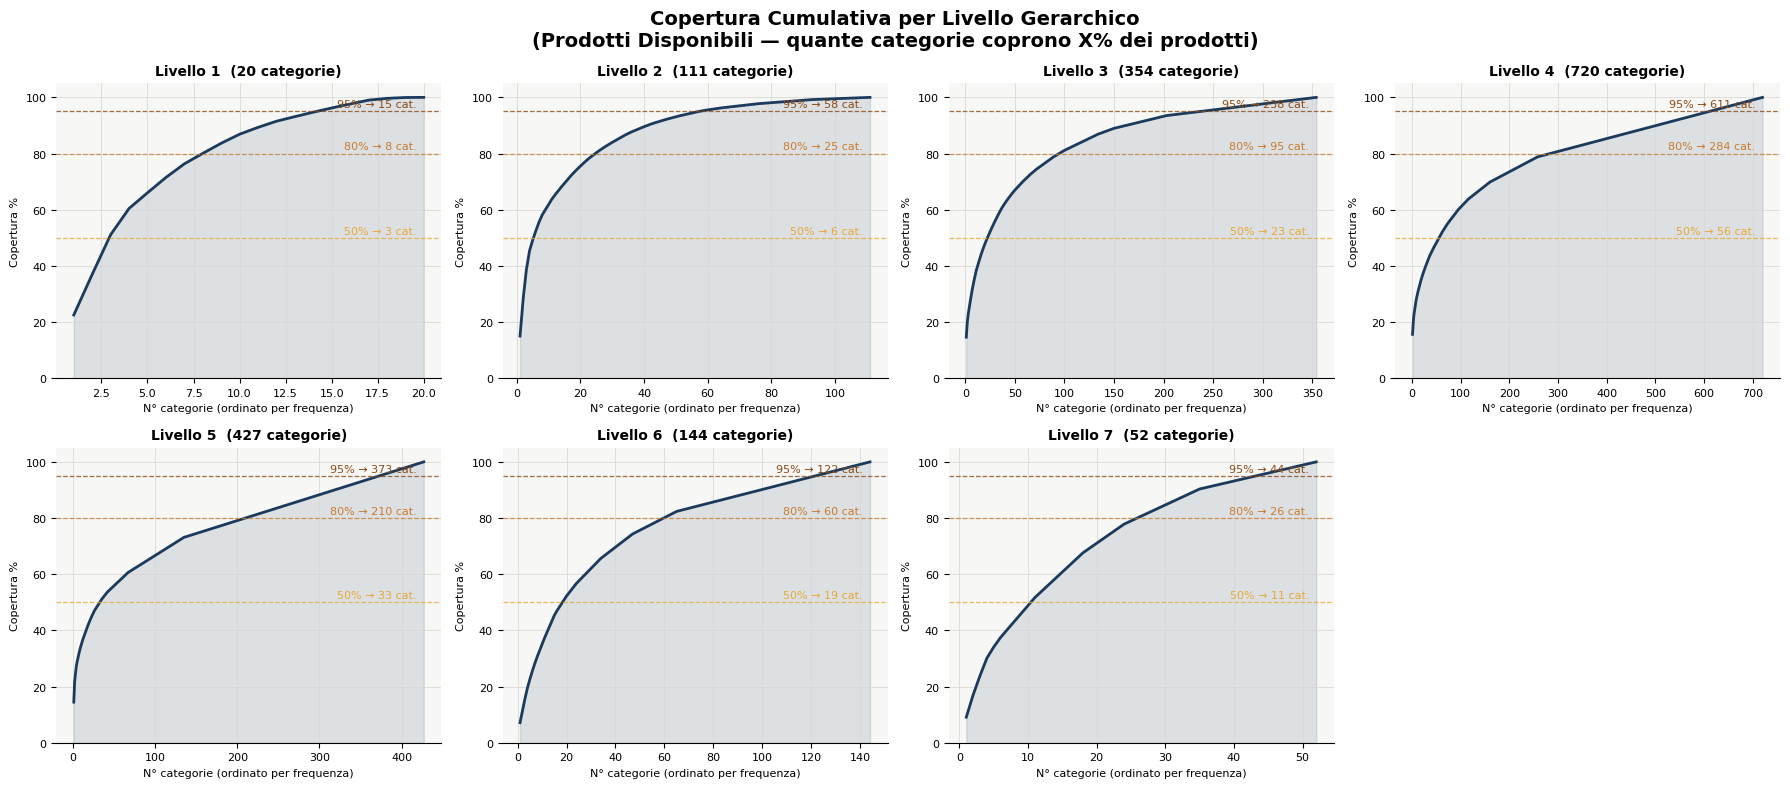

In [12]:
# Grafico: Copertura cumulativa per livello (Disponibile)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
fig.suptitle('Copertura Cumulativa per Livello Gerarchico\n(Prodotti Disponibili — quante categorie coprono X% dei prodotti)', fontsize=14, fontweight='bold')
soglie = [0.50, 0.80, 0.95]
soglie_colors = ['#E8A838', '#C97B2F', '#8B4A15']

for idx, col in enumerate(cols_disp):
    ax = axes[idx]
    serie = df_categorie_split[df_categorie_split[col] != ''][col]
    vc = serie.value_counts(normalize=True)
    cum = vc.cumsum().values
    x   = np.arange(1, len(cum) + 1)
    ax.plot(x, cum * 100, color=COL_DISP, linewidth=2)
    ax.fill_between(x, cum * 100, alpha=0.12, color=COL_DISP)

    for soglia, scol in zip(soglie, soglie_colors):
        n_cat = int(np.searchsorted(cum, soglia)) + 1
        ax.axhline(soglia * 100, color=scol, linewidth=0.9, linestyle='--', alpha=0.8)
        ax.text(len(cum) * 0.98, soglia * 100 + 1.5, f'{int(soglia*100)}% → {n_cat} cat.', ha='right', fontsize=8, color=scol)

    livello = col.replace('Categoria ', '')
    ax.set_title(f'Livello {livello}  ({serie.nunique()} categorie)', fontsize=10, fontweight='semibold')
    ax.set_xlabel('N° categorie (ordinato per frequenza)', fontsize=8)
    ax.set_ylabel('Copertura %', fontsize=8)
    ax.set_ylim(0, 105)
    ax.tick_params(labelsize=8)

axes[-1].set_visible(False)
plt.tight_layout()

In [ ]:
# Grafico: Distribuzione categorie correlate (Fuori Assortimento)
TOP_N_CORR = 15
fig, axes = plt.subplots(len(cols_corr), 1, figsize=(14, len(cols_corr) * 4.5))
fig.suptitle('Distribuzione Categorie Correlate per Livello\n(Prodotti Fuori Assortimento)', fontsize=16, fontweight='bold', y=1.01)

for ax, col in zip(axes, cols_corr):
    serie = df_categorie_split[df_categorie_split[col] != ''][col]
    n_unici = serie.nunique()
    top = serie.value_counts().head(TOP_N_CORR)
    bars = ax.barh(top.index[::-1], top.values[::-1], color=COL_CORR, alpha=0.85, height=0.65)

    for bar, val in zip(bars, top.values[::-1]):
        ax.text(bar.get_width() + max(top.values) * 0.01, bar.get_y() + bar.get_height() / 2, f'{val:,}', va='center', ha='left', fontsize=8.5, color='#333333')

    livello = col.replace('Categoria Correlata ', '')
    suffix  = f'  —  top {TOP_N_CORR} su {n_unici} valori unici' if n_unici > TOP_N_CORR else f'  —  {n_unici} valori unici (tutti mostrati)'
    ax.set_title(f'Categoria Correlata {livello}{suffix}', fontsize=11, fontweight='semibold', loc='left', pad=6)
    ax.set_xlabel('Numero di prodotti', fontsize=9)
    ax.tick_params(axis='y', labelsize=9)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.set_xlim(0, max(top.values) * 1.15)

plt.tight_layout(h_pad=2.5)


### [Output rimosso per tutela della privacy e riservatezza commerciale]

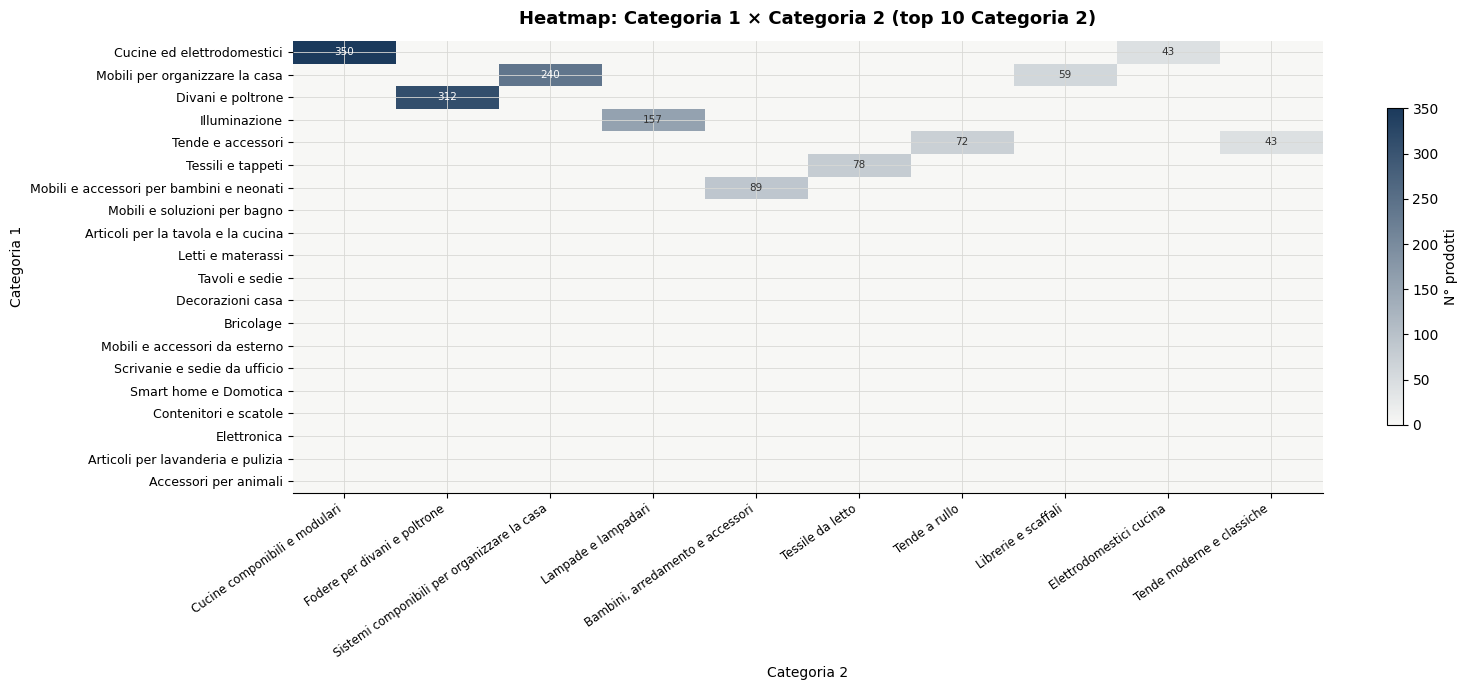

In [14]:
# Heatmap: prodotti per Categoria 1 x Categoria 2 (Disponibile)
disp_df = df_categorie_split[(df_categorie_split['Disponibilità'] == 'Disponibile') & (df_categorie_split['Categoria 1'] != '') & (df_categorie_split['Categoria 2'] != '')].copy()
pivot = (disp_df.groupby(['Categoria 1', 'Categoria 2']).size().unstack(fill_value=0))

# Ordiniamo righe e colonne per totale decrescente e teniamo solo le top 10 Categoria 2 per leggibilità
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index, pivot.sum(axis=0).sort_values(ascending=False).index]
top_cat2 = pivot.sum(axis=0).nlargest(10).index
pivot_plot = pivot[top_cat2]
fig, ax = plt.subplots(figsize=(16, 7))

cmap = mcolors.LinearSegmentedColormap.from_list('navy_amber', ['#F7F7F5', '#1B3A5C'])
im = ax.imshow(pivot_plot.values, aspect='auto', cmap=cmap)
ax.set_xticks(range(len(pivot_plot.columns)))
ax.set_xticklabels(pivot_plot.columns, rotation=35, ha='right', fontsize=8.5)
ax.set_yticks(range(len(pivot_plot.index)))
ax.set_yticklabels(pivot_plot.index, fontsize=9)

# Valori nelle celle
thresh = pivot_plot.values.max() / 2
for i in range(pivot_plot.shape[0]):
    for j in range(pivot_plot.shape[1]):
        val = pivot_plot.values[i, j]
        if val > 0:
            ax.text(j, i, str(val), ha='center', va='center', fontsize=7.5, color='white' if val > thresh else '#333333')

plt.colorbar(im, ax=ax, shrink=0.7, label='N° prodotti')
ax.set_title('Heatmap: Categoria 1 × Categoria 2 (top 10 Categoria 2)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Categoria 2', fontsize=10)
ax.set_ylabel('Categoria 1', fontsize=10)
plt.tight_layout()

In [15]:
# Riepilogo: Granularità categorie (Disponibile)
print('-' * 70)
print('Riepilogo: Granularità Categorie (Disponibile)')
print('-' * 70)
righe = []
for col in cols_disp:
    serie = df_categorie_split[df_categorie_split[col] != ''][col]
    if len(serie) == 0:
        continue
    vc   = serie.value_counts(normalize=True)
    cum  = vc.cumsum()
    righe.append({'Livello' : col, 'N° categorie uniche' : serie.nunique(), 'Top-5 coprono %' : f"{cum.iloc[min(4, len(cum)-1)]*100:.1f}%", 'Top-10 coprono %' : f"{cum.iloc[min(9, len(cum)-1)]*100:.1f}%", 'Cat. per 80% copertura': int(np.searchsorted(cum.values, 0.80)) + 1,})
display(pd.DataFrame(righe).set_index('Livello'))

print()
print('-' * 70)
print('Riepilogo: Granularità Categorie Correlate (Fuori Assortimento)')
print('-' * 70)
righe_corr = []
for col in cols_corr:
    serie = df_categorie_split[df_categorie_split[col] != ''][col]
    if len(serie) == 0:
        continue
    vc   = serie.value_counts(normalize=True)
    cum  = vc.cumsum()
    righe_corr.append({'Livello' : col, 'N° categorie uniche' : serie.nunique(), 'Top-5 coprono %' : f"{cum.iloc[min(4, len(cum)-1)]*100:.1f}%", 'Top-10 coprono %' : f"{cum.iloc[min(9, len(cum)-1)]*100:.1f}%", 'Cat. per 80% copertura': int(np.searchsorted(cum.values, 0.80)) + 1,})
display(pd.DataFrame(righe_corr).set_index('Livello'))

----------------------------------------------------------------------
Riepilogo: Granularità Categorie (Disponibile)
----------------------------------------------------------------------


,N° categorie uniche,Top-5 coprono %,Top-10 coprono %,Cat. per 80% copertura
Livello,,,,
Categoria 1,20,66.0%,86.9%,8
Categoria 2,111,49.2%,61.9%,25
Categoria 3,354,27.4%,36.7%,95
Categoria 4,720,24.0%,29.1%,284
Categoria 5,427,28.7%,34.8%,210
Categoria 6,144,22.5%,35.0%,60
Categoria 7,52,34.1%,48.9%,26



----------------------------------------------------------------------
Riepilogo: Granularità Categorie Correlate (Fuori Assortimento)
----------------------------------------------------------------------


,N° categorie uniche,Top-5 coprono %,Top-10 coprono %,Cat. per 80% copertura
Livello,,,,
Categoria Correlata 1,75,40.3%,58.3%,23
Categoria Correlata 2,77,33.6%,53.7%,28
Categoria Correlata 3,77,33.9%,53.0%,29


In [16]:
# ==============================================================================
# Colonna concatenata: Categoria Correlata (unica stringa)
cols_corr = ['Categoria Correlata 1', 'Categoria Correlata 2', 'Categoria Correlata 3']

def concatena_correlate(row):
    parti = [row[c] for c in cols_corr if row[c] != '']
    return ' > '.join(parti) if parti else ''

df_categorie_split['Categoria Correlata'] = df_categorie_split.apply(concatena_correlate, axis=1)
n_con = (df_categorie_split['Categoria Correlata'] != '').sum()
print(f"Righe con Categoria Correlata valorizzata : {n_con}.")
print(f"Righe con Categoria Correlata vuota : {len(df_categorie_split) - n_con}.")
print('-' * 70)
# ==============================================================================

# ==============================================================================
# Fallback: Categoria 2 principale, Categoria 1 se Categoria 2 è vuota
df_categorie_split['Categoria Principale'] = df_categorie_split.apply(lambda row: row['Categoria 2'] if row['Categoria 2'] != '' else row['Categoria 1'], axis=1)
n_da_cat2 = (df_categorie_split['Categoria 2'] != '').sum()
n_da_cat1 = ((df_categorie_split['Categoria 2'] == '') & (df_categorie_split['Categoria 1'] != '')).sum()
n_vuoti   = (df_categorie_split['Categoria Principale'] == '').sum()
print(f"Categoria Principale da Categoria 2 : {n_da_cat2}.")
print(f"Categoria Principale da Categoria 1 (fallback) : {n_da_cat1}.")
print(f"Categoria Principale vuota (Fuori Assortimento / Errore) : {n_vuoti}.")
# ==============================================================================

Righe con Categoria Correlata valorizzata : 372.
Righe con Categoria Correlata vuota : 2997.
----------------------------------------------------------------------
Categoria Principale da Categoria 2 : 2331.
Categoria Principale da Categoria 1 (fallback) : 0.
Categoria Principale vuota (Fuori Assortimento / Errore) : 1038.


In [21]:
# Creazione di nuovo dataset (senza modificare df_categorie_split)
df_categorie_analisi = df_categorie_split[['Numero Articolo', 'Categoria Principale', 'Categoria Correlata']]
da_recuperare = df_categorie_analisi[df_categorie_analisi['Categoria Principale'] == '']['Numero Articolo'].tolist()
print(f"Articoli con Categoria Principale mancante: {len(da_recuperare)}.")

Articoli con Categoria Principale mancante: 1038.


Il 30% del nostro catalogo second hand risulta al momento non classificabile tramite metodi diretti di scraping gerarchico. Questa evidenza giustifica e introduce metodologicamente la necessità di passare a tecniche di arricchimento più avanzate per recuperare l'informazione mancante.

### **3.4.3. Recupero delle categorie mancanti**

L'analisi si sposta ora su un approccio data-driven basato sull'elaborazione del linguaggio naturale (NLP) e sul Text Mining. L'obiettivo è **estrarre la semantica necessaria per categorizzare i prodotti privi di categoria**, attingendo ai campi testuali non strutturati già presenti nel dataset originale: la Descrizione Completa, le istruzioni di Cura e la sezione Buono a sapersi + Sicurezza e conformità.

In [17]:
# Verifica preliminare: unicità dei campi testuali per Numero Articolo Catalogo
cols_testo = ['Descrizione Completa', 'Cura', 'Buono a sapersi + Sicurezza e conformità']

for col in cols_testo:
    # Per ogni Numero Articolo Catalogo, contiamo quanti valori distinti ha quella colonna
    varianza = (df.groupby('Numero Articolo Catalogo')[col].nunique())
    non_unici = (varianza > 1).sum()
    print(f"'{col}'")
    print(f"  Articoli con valori tutti uguali : {(varianza == 1).sum()}.")
    print(f"  Articoli con valori discordanti : {non_unici}.")
    print()

'Descrizione Completa'
  Articoli con valori tutti uguali : 3276.
  Articoli con valori discordanti : 93.

'Cura'
  Articoli con valori tutti uguali : 3231.
  Articoli con valori discordanti : 0.

'Buono a sapersi + Sicurezza e conformità'
  Articoli con valori tutti uguali : 3353.
  Articoli con valori discordanti : 0.



In [ ]:
# Ispezione delle Descrizioni Complete discordanti
print("ISPEZIONE DELLE DESCRIZIONI DISCORDANTI\n")

# Troviamo i codici articolo che generano l'anomalia
anomalie = df.groupby('Numero Articolo Catalogo')['Descrizione Completa'].nunique()
codici_anomali = anomalie[anomalie > 1].index.tolist()
print(f"Isolati {len(codici_anomali)} codici articolo problematici.")
df_discordanti = df[df['Numero Articolo Catalogo'].isin(codici_anomali)][['Numero Articolo Catalogo', 'Descrizione Completa']]

# Rimuoviamo i duplicati esatti per avere solo le varianti uniche per ogni codice e raggruppiamo le varianti in una lista per renderle facili da leggere affiancate
df_varianti = df_discordanti.drop_duplicates()
df_confronto = df_varianti.groupby('Numero Articolo Catalogo')['Descrizione Completa'].apply(list).reset_index()

# Creiamo colonne separate per la 'Versione 1' e 'Versione 2' (assumendo che la maggior parte ne abbia due). Se ce ne sono di più, le lasciamo in una lista per non sfasare la tabella.
df_confronto['Versione 1'] = df_confronto['Descrizione Completa'].apply(lambda x: x[0] if len(x) > 0 else None)
df_confronto['Versione 2'] = df_confronto['Descrizione Completa'].apply(lambda x: x[1] if len(x) > 1 else None)
df_confronto['Altre Versioni'] = df_confronto['Descrizione Completa'].apply(lambda x: x[2:] if len(x) > 2 else None)
df_vista_finale = df_confronto[['Numero Articolo Catalogo', 'Versione 1', 'Versione 2', 'Altre Versioni']]

display(df_vista_finale.head(10))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# Analisi approfondita delle differenze
print("ANALISI AVANZATA DELLE DIFFERENZE")
df_analisi_diff = df_vista_finale.copy()

# Calcoliamo la differenza di lunghezza (quanti caratteri mancano o sono in più)
df_analisi_diff['Diff. Caratteri'] = abs(df_analisi_diff['Versione 1'].str.len() - df_analisi_diff['Versione 2'].str.len())

# Creiamo una funzione che calcola la percentuale di similarità tra due testi (da 0 a 100%)
def calcola_similarita(testo1, testo2):
    if pd.isna(testo1) or pd.isna(testo2):
        return 0.0
    return difflib.SequenceMatcher(None, str(testo1), str(testo2)).ratio() * 100

df_analisi_diff['Similarità %'] = df_analisi_diff.apply(lambda row: round(calcola_similarita(row['Versione 1'], row['Versione 2']), 1), axis=1)

# Classifichiamo il tipo di anomalia
# Se sono uguali al 95% o più, è un refuso. Altrimenti è una differenza sostanziale (combo vs pezzo singolo)
df_analisi_diff['Tipo Discrepanza'] = df_analisi_diff['Similarità %'].apply(lambda x: 'Lieve (Refuso/Punteggiatura)' if x >= 95 else 'Sostanziale (Possibile Set/Combo)')

# Riordiniamo le colonne per una lettura più facile
colonne_ordinate = ['Numero Articolo Catalogo', 'Tipo Discrepanza', 'Similarità %', 'Diff. Caratteri', 'Versione 1', 'Versione 2']
display(df_analisi_diff[colonne_ordinate].head(10))

# Quanti sono refusi e quanti sono combo?
print("\nRiassunto tipo di discrepanze:")
print(df_analisi_diff['Tipo Discrepanza'].value_counts())

# Casi Sostanziali
print("\nCasi Sostanziali:")
display(df_analisi_diff[df_analisi_diff['Tipo Discrepanza'] == 'Sostanziale (Possibile Set/Combo)'][colonne_ordinate])


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [22]:
# ==============================================================================
# Preparazione dei campi testuali: la strategia è considerare la descrizione più lunga per i disomogenei
df['Numero Articolo Catalogo'] = df['Numero Articolo Catalogo'].astype(str).str.replace(r'\.0$', '', regex=True)
df_testo = df[['Numero Articolo Catalogo', 'Cura', 'Buono a sapersi + Sicurezza e conformità']].drop_duplicates(subset='Numero Articolo Catalogo')

# Per ogni codice prendiamo la stringa più lunga (gestendo anche i NaN)
desc_lunga = (df[['Numero Articolo Catalogo', 'Descrizione Completa']].assign(lung=df['Descrizione Completa'].str.len().fillna(0)).sort_values('lung', ascending=False).drop_duplicates(subset='Numero Articolo Catalogo').drop(columns='lung'))

df_testo = df_testo.merge(desc_lunga, on='Numero Articolo Catalogo', how='left')
print(f"Record unici in df_testo: {len(df_testo)}.")
# ==============================================================================

# ==============================================================================
# Merge: df_categorie_analisi + campi testuali
df_categorie_analisi['Numero Articolo'] = df_categorie_analisi['Numero Articolo'].astype(str)
df_categorie_analisi = df_categorie_analisi.merge(df_testo, left_on='Numero Articolo', right_on='Numero Articolo Catalogo', how='left').drop(columns='Numero Articolo Catalogo')
print(f"Dimensioni df_categorie_analisi : {df_categorie_analisi.shape}.")
print(f"Colonne : {df_categorie_analisi.columns.tolist()}.")
print(f"Righe preservate: {'Sì' if len(df_categorie_analisi) == 3369 else 'No, attenzione'}.")
# ==============================================================================

Record unici in df_testo: 3369.
Dimensioni df_categorie_analisi : (3369, 6).
Colonne : ['Numero Articolo', 'Categoria Principale', 'Categoria Correlata', 'Cura', 'Buono a sapersi + Sicurezza e conformità', 'Descrizione Completa'].
Righe preservate: Sì.


In [23]:
# Verifica copertura dei campi testuali per gli articoli senza categoria
cols_testo = ['Descrizione Completa', 'Cura', 'Buono a sapersi + Sicurezza e conformità']
da_recuperare = df_categorie_analisi[df_categorie_analisi['Categoria Principale'] == ''].copy()

def flag(val):
    return '✅' if pd.notna(val) and str(val).strip() != '' else '❌'

vista = da_recuperare[['Numero Articolo'] + cols_testo].copy()
vista['Descrizione Completa'] = vista['Descrizione Completa'].apply(flag)
vista['Cura'] = vista['Cura'].apply(flag)
vista['Buono a sapersi + Sicurezza e conformità'] = vista['Buono a sapersi + Sicurezza e conformità'].apply(flag)
vista.columns = ['Numero Articolo', 'Desc.', 'Cura', 'Buono a sapersi']

mask_tutti = (vista['Desc.'] == '✅') & (vista['Cura'] == '✅') & (vista['Buono a sapersi'] == '✅')
mask_nessuno = (vista['Desc.'] == '❌') & (vista['Cura'] == '❌') & (vista['Buono a sapersi'] == '❌')
mask_parziale = ~mask_tutti & ~mask_nessuno

n_tutti = mask_tutti.sum()
n_parziale = mask_parziale.sum()
n_nessuno = mask_nessuno.sum()

print(f"Articoli senza Categoria Principale : {len(da_recuperare)}.")
print(f"Con tutti e 3 i campi valorizzati : {n_tutti} ({n_tutti / len(da_recuperare) * 100:.1f}%).")
print(f"Con almeno uno ma non tutti i campi : {n_parziale} ({n_parziale / len(da_recuperare) * 100:.1f}%).")
print(f"Senza nessun campo testuale : {n_nessuno} ({n_nessuno / len(da_recuperare) * 100:.1f}%).")
print()

print("Distribuzione combinazioni:")
display(vista.groupby(['Desc.', 'Cura', 'Buono a sapersi']).size().reset_index(name='Conteggio'))

print()
print("Esempi di articoli con almeno uno ma non tutti i campi:")
display(vista[mask_parziale].head(15))

Articoli senza Categoria Principale : 1038.
Con tutti e 3 i campi valorizzati : 975 (93.9%).
Con almeno uno ma non tutti i campi : 63 (6.1%).
Senza nessun campo testuale : 0 (0.0%).

Distribuzione combinazioni:


,Desc.,Cura,Buono a sapersi,Conteggio
0,✅,✅,✅,975
1,✅,❌,✅,56
2,✅,❌,❌,7



Esempi di articoli con almeno uno ma non tutti i campi:


,Numero Articolo,Desc.,Cura,Buono a sapersi
38,60440510,✅,❌,✅
42,90265760,✅,❌,✅
74,00558994,✅,❌,❌
188,90440472,✅,❌,✅
204,20000141,✅,❌,❌
214,60564138,✅,❌,✅
437,60559815,✅,❌,✅
458,80504836,✅,❌,✅
470,20606654,✅,❌,✅
520,40593684,✅,❌,✅


Prima di passare all'impiego di differenti approcci complementari per assegnare una categoria principale ai 1038 articoli per cui non è stato possibile recuperarla direttamente dallo scraping, prepariamo i dati.

In [24]:
cols_testo = ['Descrizione Completa', 'Cura', 'Buono a sapersi + Sicurezza e conformità']

def build_testo(row):
    parti = [str(row[c]) for c in cols_testo if pd.notna(row[c]) and str(row[c]).strip() != '']
    return ' '.join(parti).strip()

df_categorie_analisi['testo'] = df_categorie_analisi.apply(build_testo, axis=1)
df_noti   = df_categorie_analisi[df_categorie_analisi['Categoria Principale'] != ''].copy()
df_orfani = df_categorie_analisi[df_categorie_analisi['Categoria Principale'] == ''].copy()

CATEGORIE_L2 = sorted(df_noti['Categoria Principale'].unique().tolist())

print(f"Articoli noti (training) : {len(df_noti)}.")
print(f"Articoli orfani : {len(df_orfani)}.")
print(f"Categorie (Livello 2) note : {len(CATEGORIE_L2)}.")

Articoli noti (training) : 2331.
Articoli orfani : 1038.
Categorie (Livello 2) note : 111.


In [25]:
# Treemap Interattivo
# Calcoliamo la frequenza di ogni Categoria di Livello 2 dal dataset noto e generiamo il Treemap
df_counts = df_noti['Categoria Principale'].value_counts().reset_index()
df_counts.columns = ['Categoria', 'Conteggio']

fig = px.treemap(df_counts, path=[px.Constant("Assortimento"), 'Categoria'], values='Conteggio', title=f'Treemap Interattivo: Distribuzione delle {len(CATEGORIE_L2)} Categorie Note', color='Conteggio',  color_continuous_scale='Blues')
fig.update_traces(root_color="lightgrey", textinfo="label+value")
fig.update_layout(margin=dict(t=50, l=25, r=25, b=25), height=800)
fig.show()

Per istruire un algoritmo di classificazione testuale, è metodologicamente necessario definire a priori lo spazio delle etichette target verso cui ricondurre gli articoli attualmente orfani. Esplorando l'architettura dell'e-commerce ufficiale, è emersa un'importante ipotesi strutturale. Le macro-aree principali del portale contengono elenchi specifici di sotto-categorie (ad esempio, aprendo la sezione "Articoli per la tavola e la cucina" si accede a sezioni come "Posate", "Accessori cucina", "Biancheria da cucina", ecc.). L'intuizione, che si anticipa essere corretta, è che queste specifiche sotto-sezioni del sito coincidano esattamente con il "Livello 2" del percorso di navigazione che abbiamo estratto in precedenza.

In [ ]:
print("Verifica corrispondeza tra le Categorie di Livello 2 e la lista ufficiale di tutte le categorie presenti sul sito:")

# La lista di ben 215 categorie ufficiali
lista_categorie_ufficiale = ["[redacted]"]

# Normalizzazione: convertiamo tutto in minuscolo e togliamo gli spazi extra, al fine di prevenire falsi negativi dovuti a maiuscole o spazi invisibili
set_ufficiale = {cat.strip().lower() for cat in lista_categorie_ufficiale}
set_l2 = {cat.strip().lower() for cat in CATEGORIE_L2}

# Intersezione e Differenza
# Quali categorie di L2 sono presenti nella lista ufficiale?
match_trovati = set_l2.intersection(set_ufficiale)

# Quali categorie di L2 mancano nella lista ufficiale?
non_trovati = set_l2.difference(set_ufficiale)

# Statistiche
print(f"-> Totale categorie di quelle principali (di livello 2) già note: {len(CATEGORIE_L2)}.")
print(f"-> Totale categorie nella lista ufficiale: {len(lista_categorie_ufficiale)}.")
print(f"-> Match trovati: {len(match_trovati)}.")
print(f"-> Categorie note non trovate nella lista ufficiale: {len(non_trovati)}.\n")

# Visualizzazione in tabella delle categorie non trovate (se ci sono)
if non_trovati:
    print("Dettaglio categorie non trovate nella lista ufficiale:")
    # Recuperiamo il nome originale della categoria (con le maiuscole giuste) per chiarezza visiva
    cat_originali_non_trovate = [cat for cat in CATEGORIE_L2 if cat.strip().lower() in non_trovati]
    df_non_trovati = pd.DataFrame(cat_originali_non_trovate, columns=['Categoria L2 mancante nella lista 215'])
    display(df_non_trovati)
else:
    print("Tutte le tue categorie già note sono incluse nella lista ufficiale delle categorie presenti sul sito.")

Verifica corrispondeza tra le Categorie di Livello 2 e la lista ufficiale di tutte le categorie presenti sul sito:
-> Totale categorie di quelle principali (di livello 2) già note: 111.
-> Totale categorie nella lista ufficiale: 215.
-> Match trovati: 111.
-> Categorie note non trovate nella lista ufficiale: 0.

Tutte le tue categorie già note sono incluse nella lista ufficiale delle categorie presenti sul sito.


In [ ]:
# Funzione per normalizzare il testo (rimuozione di spazi e punteggiatura) per un match infallibile
def normalizza(testo):
    return re.sub(r'[^a-z0-9]', '', str(testo).lower())

def estrai_link_da_json(obj, mappa):
    if isinstance(obj, dict):
        titolo = obj.get('title') or obj.get('name')
        url = obj.get('url') or obj.get('link')
        if titolo and url and '/cat/' in url:
            if url.startswith('/'):
                url = "https://www.[redacted].com" + url
            mappa[normalizza(titolo)] = url
        for k, v in obj.items():
            estrai_link_da_json(v, mappa)
    elif isinstance(obj, list):
        for item in obj:
            estrai_link_da_json(item, mappa)

def estrai_tutto():
    # La lista completa delle categorie ufficiali (livello 2)
    lista_categorie_ufficiale = ["[redacted]"]
    
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36", "Accept-Language": "it-IT,it;q=0.9"}
    
    print("Mappatura completa del catalogo in corso...")
    url_prodotti = "https://www.[redacted].com/it/it/cat/prodotti-products/"
    
    try:
        res = requests.get(url_prodotti, headers=headers)
        res.raise_for_status()
        soup = BeautifulSoup(res.text, 'html.parser')
    except Exception as e:
        print("Errore di connessione:", e)
        return

    mappa_link = {}
    
    # Estrazione dai link visibili
    for a in soup.find_all('a', href=True):
        nome = a.text.strip()
        if nome and '/cat/' in a['href']:
            link = a['href']
            if link.startswith('/'): link = "https://www.[redacted].com" + link
            mappa_link[normalizza(nome)] = link

    # Estrazione profonda dai dati nascosti
    scripts = soup.find_all('script', type='text/hydrate')
    for script in scripts:
        if script.string and '{' in script.string:
            try:
                data = json.loads(script.string)
                estrai_link_da_json(data, mappa_link)
            except:
                pass

    print(f"-> Mappatura completata. Trovati {len(mappa_link)} link univoci.\n")
    print("-" * 50)
    
    # Dizionario per il salvataggio in json
    risultati_finali = {}

    # Iteriamo sulla lista
    for nome_cat in lista_categorie_ufficiale:
        nome_norm = normalizza(nome_cat)
        url_cat = mappa_link.get(nome_norm)
        
        # Fallback: ricerca parziale
        if not url_cat:
            for chiave_mappa, link in mappa_link.items():
                if nome_norm in chiave_mappa or chiave_mappa in nome_norm:
                    url_cat = link
                    break
                    
        if not url_cat:
            print(f"{nome_cat} -> [LINK NON TROVATO]")
            continue
            
        # Visitiamo e usiamo i BREADCRUMBS (hierarchyObjs)
        try:
            res_cat = requests.get(url_cat, headers=headers)
            soup_cat = BeautifulSoup(res_cat.text, 'html.parser')
            scripts_cat = soup_cat.find_all('script', type='text/hydrate')
            
            sottocategorie = []
            trovato = False
            
            for script in scripts_cat:
                if script.string and '"hierarchyObjs"' in script.string:
                    try:
                        data = json.loads(script.string)
                        breadcrumbs = data.get('data', {}).get('hierarchyObjs', [])
                        
                        if breadcrumbs:
                            # Prendiamo l'ultimo elemento: è sempre la categoria attuale esatta
                            nodo_corrente = breadcrumbs[-1]
                            sub_cats = nodo_corrente.get('subCategories', [])
                            
                            for sub in sub_cats:
                                titolo = sub.get('title') or sub.get('name')
                                if titolo and titolo.strip():
                                    sottocategorie.append(titolo.strip())
                            
                            trovato = True
                            break 
                    except json.JSONDecodeError:
                        continue
                        
            if trovato:
                sottocategorie_uniche = list(dict.fromkeys(sottocategorie))
                print(f"{nome_cat} {sottocategorie_uniche}")
                risultati_finali[nome_cat] = sottocategorie_uniche
            else:
                print(f"{nome_cat} []")
                risultati_finali[nome_cat] = []

            time.sleep(1) 
            
        except Exception as e:
            print(f"{nome_cat} -> [ERRORE DI CONNESSIONE: {e}]")
            risultati_finali[nome_cat] = []

    # Salvataggio in json nella cartella di estrazione delle categorie più recente
    cartella_base = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
    cartelle_estrazione = sorted(cartella_base.glob("Estrazione Categorie__*"), reverse=True)
    if cartelle_estrazione:
        cartella_piu_recente = cartelle_estrazione[0]
        percorso_file = cartella_piu_recente / "2_sottocategorie.json"
        
        # Salviamo il file
        with open(percorso_file, 'w', encoding='utf-8') as f:
            json.dump(risultati_finali, f, ensure_ascii=False, indent=4)
            
        print("\n" + "-" * 50)
        print(f"Estrazione completata! File salvato con successo in:\n{percorso_file}.")
        
    else:
        # Se non trova nessuna cartella con quel nome, ci avvisa e lo salva nella cartella base
        cartella_base.mkdir(parents=True, exist_ok=True)
        percorso_fallback = cartella_base / "categorie_[redacted].json"
        
        with open(percorso_fallback, 'w', encoding='utf-8') as f:
            json.dump(risultati_finali, f, ensure_ascii=False, indent=4)
            
        print("\n" + "-" * 50)
        print(f"Nessuna cartella 'Estrazione Categorie__*' trovata.")
        print(f"File salvato nel percorso di fallback:\n{percorso_fallback}.")

if __name__ == "__main__":
    estrai_tutto()


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [27]:
# Lettura del file nella cartella di estrazione delle categorie più recente

if cartelle_estrazione:
    cartella_piu_recente = cartelle_estrazione[0]
    file_json = cartella_piu_recente / "2_sottocategorie.json"
    
    # Verifichiamo che il file esista per evitare errori
    if file_json.exists():
        print(f"File identificato e in caricamento: {file_json.name}.")
        
        # Apriamo e carichiamo il file nel nostro dizionario
        with open(file_json, 'r', encoding='utf-8') as f:
            dizionario_categorie = json.load(f)
            
        print(f"Caricamento completato! Trovate {len(dizionario_categorie)} categorie.")
        
        # Controllo statistiche
        cat_piene = 0
        cat_vuote = 0
        cat_link_non_trovato = 0
        cat_errore = 0
        
        for categoria, sottocategorie in dizionario_categorie.items():
            testo_da_controllare = str(sottocategorie).upper()
            # Controlliamo se è un "LINK NON TROVATO"
            if "LINK NON TROVATO" in testo_da_controllare:
                cat_link_non_trovato += 1
            # Controlliamo se c'è un errore di connessione/timeout registrato
            elif "ERRORE" in testo_da_controllare:
                cat_errore += 1
            # Controlliamo se la lista è genuinamente vuota [] (nessuna sottocategoria sul sito)
            elif len(sottocategorie) == 0:
                cat_vuote += 1
            # Altrimenti, ha estratto regolarmente delle sottocategorie
            else:
                cat_piene += 1
                
        # Stampiamo il riepilogo
        print("\nRiepilogo:")
        print(f"-> Categorie con sottocategorie valide: {cat_piene}.")
        print(f"-> Categorie vuote: {cat_vuote}.")
        print(f"-> Categorie con link non trovato: {cat_link_non_trovato}.")
        print(f"-> Categorie con errore di connessione: {cat_errore}.")

        # Esempio pratico: stampiamo le sottocategorie di una voce a caso
        print("\nEcco le sottocategorie di 'Sedie per bambini':")
        print(dizionario_categorie.get("Sedie per bambini", "Categoria non presente"))
        
    else:
        print(f"Errore: Il file '2_sottocategorie.json' non si trova nella cartella {cartella_piu_recente.name}.")

else:
    print("Errore: Nessuna cartella di estrazione trovata.")

File identificato e in caricamento: 2_sottocategorie.json.
Caricamento completato! Trovate 191 categorie.

Riepilogo:
-> Categorie con sottocategorie valide: 107.
-> Categorie vuote: 84.
-> Categorie con link non trovato: 0.
-> Categorie con errore di connessione: 0.

Ecco le sottocategorie di 'Sedie per bambini':
['Poltroncine e seggiolini per bambini', 'Sedie da scrivania per cameretta', 'Sgabelli e panche per bambini', 'Poltrone per bambini', 'Sedie junior e sedie per ragazzi']


-> **Approccio 1: Euristica sulle Categorie Correlate**

Il primo approccio sfrutta un'informazione già disponibile nel dataset: la colonna `Categoria Correlata`, presente per gli articoli Fuori Assortimento che durante lo scraping hanno restituito suggerimenti di navigazione dal sito dell'azienda. 

In [ ]:
orfani_con_correlata = df_orfani[df_orfani['Categoria Correlata'] != ''].copy()
print(f"Orfani con Categoria Correlata : {len(orfani_con_correlata)}")

def cerca_categoria_in_correlata(stringa_correlata, categorie_l2):
    livelli = [s.strip().lower() for s in stringa_correlata.split('>')]
    match = [c for c in lista_categorie_ufficiale if c.lower() in livelli]
    
    if len(match) == 1:
        return match[0], 1
    elif len(match) > 1:
        return None, len(match)
    else:
        return None, 0

risultati = orfani_con_correlata['Categoria Correlata'].apply(
    lambda s: cerca_categoria_in_correlata(s, lista_categorie_ufficiale)
)

orfani_con_correlata[['cat_euristica', 'n_match']] = pd.DataFrame(risultati.tolist(), index=orfani_con_correlata.index)

risultati_euristica = orfani_con_correlata[orfani_con_correlata['cat_euristica'].notna()].copy()
ambigui_euristica   = orfani_con_correlata[orfani_con_correlata['n_match'] > 1]
nessun_match        = orfani_con_correlata[orfani_con_correlata['n_match'] == 0]

print(f"\nMatch univoco (assegnazione diretta) : {len(risultati_euristica)}.")
print(f"Match ambiguo (più categorie trovate): {len(ambigui_euristica)}.")
print(f"Nessun match                         : {len(nessun_match)}.")

print("\nDistribuzione categorie assegnate per euristica:")
display(risultati_euristica['cat_euristica'].value_counts().reset_index().set_axis(['Categoria', 'Conteggio'], axis=1))

Orfani con Categoria Correlata : 372

Match univoco (assegnazione diretta) : 44.
Match ambiguo (più categorie trovate): 21.
Nessun match                         : 307.

Distribuzione categorie assegnate per euristica:


,Categoria,Conteggio
0,Scarpiere,16
1,Comodini,5
2,Mobili alti e scaffali per il bagno,5
3,Coperte e plaid,5
4,Miscelatori cucina,2
5,Carrelli e isole cucina,2
6,Seggioloni per bambini,2
7,Pensili per bagno,1
8,Lavelli cucina,1
9,Accessori per scrivania,1


In [ ]:
# ==============================================================================
# Esempi di match univoco (assegnazione diretta)
print("Esempi di match univoco (assegnazione diretta)")

if len(risultati_euristica) > 0:
    colonne_univoci = ['Numero Articolo', 'Descrizione Completa', 'Categoria Correlata', 'cat_euristica']
    display(risultati_euristica[colonne_univoci].head(5))
else:
    print("Nessun record con match univoco.")

print("\n" + "-"*80 + "\n")
# ==============================================================================

# ==============================================================================
# Esempi di record ambigui (più categorie trovate)
print("Esempi di record ambigui (più categorie trovate)")

if len(ambigui_euristica) > 0:
    colonne_ambigui = ['Numero Articolo', 'Descrizione Completa', 'Categoria Correlata', 'n_match']
    display(ambigui_euristica[colonne_ambigui].head(5))
else:
    print("Nessun record con match ambiguo.")

print("\n" + "-"*80 + "\n")
# ==============================================================================

# ==============================================================================
# Esempi di nessun match (nessuna corrispondenza individuata)
print("Esempi di nessun match (nessuna corrispondenza individuata)")

if len(nessun_match) > 0:
    colonne_nessun_match = ['Numero Articolo', 'Descrizione Completa', 'Categoria Correlata']
    display(nessun_match[colonne_nessun_match].head(5))
else:
    print("Nessun record senza match.")
# ==============================================================================


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Approccio 2: Information Retrieval (TF-IDF + Cosine Similarity)**

Il secondo approccio si basa su una tecnica di Information Retrieval (recupero dell'informazione): l'idea di fondo è che prodotti con descrizioni testuali molto simili appartengano alla stessa categoria merceologica. Per ogni articolo orfano si cerca il "gemello testuale" più simile tra i 2.331 articoli con categoria già nota, e se ne eredita la categoria.

Matrice articoli con categoria nota: (2331, 8708).
Matrice articoli senza categoria: (1038, 8708).

Score minimo : 0.1055.
Score massimo : 1.0000.
Score medio : 0.5620.
Score mediano : 0.5376.


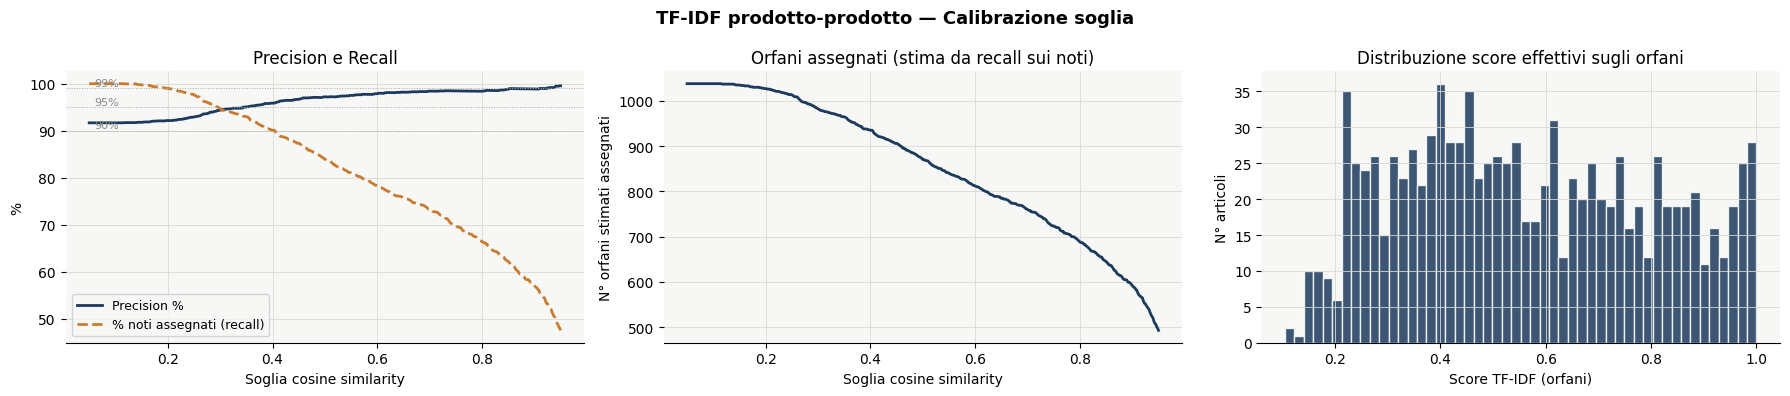


Tabella soglie (fascia alta):



,Soglia,Precision %,Orfani assegnati,Residui → Gemini
0,0.50,97.2,573,465
1,0.55,97.5,498,540
2,0.60,97.9,441,597
3,0.65,98.2,384,654
4,0.70,98.4,323,715
5,0.75,98.5,262,776
6,0.80,98.4,217,821
7,0.85,98.8,156,882
8,0.90,98.9,110,928
9,0.95,99.5,64,974


In [31]:
# FIT sugli articoli per i quali è nota la categoria, TRANSFORM su quelli noti e orfani
vectorizer = TfidfVectorizer(sublinear_tf=True)
tfidf_noti = vectorizer.fit_transform(df_noti['testo'])
tfidf_orfani = vectorizer.transform(df_orfani['testo'])
print(f"Matrice articoli con categoria nota: {tfidf_noti.shape}.")
print(f"Matrice articoli senza categoria: {tfidf_orfani.shape}.")

# RETRIEVAL: per ogni orfano si trova il noto più simile
sim_matrix = cosine_similarity(tfidf_orfani, tfidf_noti) 
idx_max = sim_matrix.argmax(axis=1)
score_max = sim_matrix.max(axis=1)

df_orfani = df_orfani.copy()
df_orfani['cat_tfidf'] = df_noti['Categoria Principale'].iloc[idx_max].values
df_orfani['score_tfidf'] = score_max
df_orfani['gemello_tfidf'] = df_noti['Numero Articolo'].iloc[idx_max].values

print(f"\nScore minimo : {score_max.min():.4f}.")
print(f"Score massimo : {score_max.max():.4f}.")
print(f"Score medio : {score_max.mean():.4f}.")
print(f"Score mediano : {np.median(score_max):.4f}.")

# Calibrazione: leave-one-out sui noti
# Per ogni articolo noto, lo trattiamo come se fosse un orfano: troviamo il suo gemello tra i restanti noti e registriamo (score, giusto/sbagliato). Questo ci dice a che soglia fidarci.
categorie_noti = df_noti['Categoria Principale'].values
n = tfidf_noti.shape[0]
scores_val = np.zeros(n)
corretti_val = np.zeros(n, dtype=bool)

for i in range(n):
    sim_row   = cosine_similarity(tfidf_noti[i], tfidf_noti)[0]
    sim_row[i] = 0              # si esclude se stesso
    best_j = sim_row.argmax()
    scores_val[i] = sim_row[best_j]
    corretti_val[i] = (categorie_noti[best_j] == categorie_noti[i])

# Curva precision / recall al variare della soglia
soglie = np.linspace(0.05, 0.95, 500)
prec_list, rec_list, n_list = [], [], []

for s in soglie:
    mask = scores_val >= s
    if mask.sum() == 0:
        prec_list.append(np.nan); rec_list.append(0); n_list.append(0)
        continue
    prec_list.append(corretti_val[mask].mean())
    rec_list.append(mask.mean())
    n_list.append(mask.sum())

prec_arr = np.array(prec_list)
rec_arr  = np.array(rec_list)
n_arr    = np.array(n_list)

# Grafici
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle('TF-IDF prodotto-prodotto — Calibrazione soglia', fontsize=13, fontweight='bold')

axes[0].plot(soglie, prec_arr * 100, color='#1B3A5C', lw=2, label='Precision %')
axes[0].plot(soglie, rec_arr  * 100, color='#C97B2F', lw=2, ls='--', label='% noti assegnati (recall)')
for liv in [90, 95, 99]:
    axes[0].axhline(liv, color='#AAAAAA', lw=0.7, ls=':')
    axes[0].text(0.06, liv + 0.5, f'{liv}%', fontsize=8, color='#888')
axes[0].set_xlabel('Soglia cosine similarity')
axes[0].set_ylabel('%')
axes[0].set_title('Precision e Recall')
axes[0].legend(fontsize=9)

n_orfani_attesi = (rec_arr * len(df_orfani)).astype(int)
axes[1].plot(soglie, n_orfani_attesi, color='#1B3A5C', lw=2)
axes[1].set_xlabel('Soglia cosine similarity')
axes[1].set_ylabel('N° orfani stimati assegnati')
axes[1].set_title('Orfani assegnati (stima da recall sui noti)')

axes[2].hist(score_max, bins=50, color='#1B3A5C', alpha=0.85, edgecolor='white')
axes[2].set_xlabel('Score TF-IDF (orfani)')
axes[2].set_ylabel('N° articoli')
axes[2].set_title('Distribuzione score effettivi sugli orfani')
plt.tight_layout()
plt.show()

# Tabella di riferimento
soglie_tab = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
rows = []
for s in soglie_tab:
    mask_val  = scores_val >= s
    mask_orf  = score_max  >= s
    prec      = corretti_val[mask_val].mean() * 100 if mask_val.sum() > 0 else np.nan
    n_orf_ass = mask_orf.sum()
    n_residui = len(df_orfani) - n_orf_ass
    rows.append({'Soglia' : s, 'Precision %' : round(prec, 1), 'Orfani assegnati': n_orf_ass, 'Residui → Gemini': n_residui,})
    
print("\nTabella soglie (fascia alta):\n")
display(pd.DataFrame(rows))

In [ ]:
# Scelta della soglia
SOGLIA = 0.70

mask_ok = df_orfani['score_tfidf'] >= SOGLIA
df_assegnati_tfidf = df_orfani[mask_ok].copy()
df_residui_gemini  = df_orfani[~mask_ok].copy()
df_assegnati_tfidf['Categoria Principale Predetta'] = df_assegnati_tfidf['cat_tfidf']
df_assegnati_tfidf['fonte_classificazione']  = 'TF-IDF'
df_assegnati_tfidf['score_confidenza']  = df_assegnati_tfidf['score_tfidf']
df_border = df_assegnati_tfidf.copy()
df_border['dist'] = df_border['score_tfidf'] - SOGLIA
prec_effettiva = corretti_val[scores_val >= SOGLIA].mean() * 100

print(f"Soglia scelta : {SOGLIA}.")
print(f"Precision (validation set) : {prec_effettiva:.1f}%.")
print("\n" + "-"*50)

# Esempi score più alto
print("\nEsempi assegnati (score più alto):")
top5 = df_assegnati_tfidf.nlargest(2, 'score_tfidf')[['Numero Articolo', 'score_tfidf', 'Categoria Principale Predetta', 'gemello_tfidf', 'testo']].copy()
top5 = top5.merge(df_noti[['Numero Articolo', 'testo']].rename(columns={'Numero Articolo': 'gemello_tfidf', 'testo': 'testo_gemello'}),on='gemello_tfidf', how='left')
pd.set_option('display.max_colwidth', 300)
for _, row in top5.iterrows():
    display(
        pd.DataFrame({''       : ['Orfano', 'Gemello'],
            'Articolo': [row['Numero Articolo'], row['gemello_tfidf']],
            'Testo'   : [row['testo'][:300] + '...', row['testo_gemello'][:300] + '...'],})
            .set_index('').style.set_caption(f"Score: {row['score_tfidf']:.4f}  |  Categoria assegnata: {row['Categoria Principale Predetta']}").set_properties(**{'text-align': 'left', 'white-space': 'normal'}))
pd.reset_option('display.max_colwidth')
print("\n" + "-"*50)

# Esempi score vicino alla soglia
print("\nEsempi assegnati (score più vicino alla soglia):")
border5 = df_border.nsmallest(10, 'dist')[['Numero Articolo', 'score_tfidf', 'Categoria Principale Predetta', 'gemello_tfidf', 'testo']].copy()
border5 = border5.merge(df_noti[['Numero Articolo', 'testo']].rename(columns={'Numero Articolo': 'gemello_tfidf','testo'  : 'testo_gemello'}), on='gemello_tfidf', how='left')
pd.set_option('display.max_colwidth', 300)
for _, row in border5.iterrows():
    display(
        pd.DataFrame({''       : ['Orfano', 'Gemello'],
            'Articolo': [row['Numero Articolo'], row['gemello_tfidf']],
            'Testo'   : [row['testo'][:300] + '...', row['testo_gemello'][:300] + '...'],})
        .set_index('').style.set_caption(f"Score: {row['score_tfidf']:.4f}  |  Categoria assegnata: {row['Categoria Principale Predetta']}").set_properties(**{'text-align': 'left', 'white-space': 'normal'}))
pd.reset_option('display.max_colwidth')
print("\n" + "-"*50)

# Distribuzione categorie assegnate
print("\nTop 10 categorie assegnate da TF-IDF:")
display(df_assegnati_tfidf['Categoria Principale Predetta'].value_counts().head(10).reset_index().set_axis(['Categoria', 'Conteggio'], axis=1))

print("\n" + "-"*50)
print("Riepilogo:")
print(f"-> TF-IDF assegnati : {len(df_assegnati_tfidf):4d} / 1038.")
print(f"-> Residui da passare a Gemini  : {len(df_residui_gemini):4d} / 1038.")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Approccio 3: LLM Zero-Shot con Gemini**

Per affrontare la classificazione degli articoli orfani rimasti privi di categoria dopo l'approccio TF-IDF, viene implementata una strategia basata su modelli linguistici di grandi dimensioni (Large Language Models, LLM). Quando i metodi classici fondati sulla sovrapposizione di parole chiave mostrano dei limiti, dovuti alla variabilità del lessico o all'assenza di un gemello testuale sufficientemente simile nel training set, l'adozione dell'Intelligenza Artificiale Generativa permette di sfruttare una comprensione semantica profonda e capacità inferenziali avanzate. L'approccio scelto è di tipo Zero-Shot Learning: il modello esegue il compito di classificazione senza aver ricevuto esempi specifici nel prompt. Si affida esclusivamente alle proprie conoscenze pregresse e alle istruzioni contestuali fornite per dedurre la risposta corretta. 

In [ ]:
API_KEY = '[secret]'
genai.configure(api_key=API_KEY)

#  Verifica modelli disponibili
print("Modelli disponibili:\n")
for m in genai.list_models():
    if 'generateContent' in m.supported_generation_methods:
        print(f"  {m.name}")

Modelli disponibili:

  models/gemini-2.5-flash
  models/gemini-2.5-pro
  models/gemini-2.0-flash
  models/gemini-2.0-flash-001
  models/gemini-2.0-flash-lite-001
  models/gemini-2.0-flash-lite
  models/gemini-2.5-flash-preview-tts
  models/gemini-2.5-pro-preview-tts
  models/gemma-4-26b-a4b-it
  models/gemma-4-31b-it
  models/gemini-flash-latest
  models/gemini-flash-lite-latest
  models/gemini-pro-latest
  models/gemini-2.5-flash-lite
  models/gemini-2.5-flash-image
  models/gemini-3-pro-preview
  models/gemini-3-flash-preview
  models/gemini-3.1-pro-preview
  models/gemini-3.1-pro-preview-customtools
  models/gemini-3.1-flash-lite-preview
  models/gemini-3.1-flash-lite
  models/gemini-3-pro-image-preview
  models/gemini-3-pro-image
  models/nano-banana-pro-preview
  models/gemini-3.1-flash-image-preview
  models/gemini-3.1-flash-image
  models/gemini-3.5-flash
  models/lyria-3-clip-preview
  models/lyria-3-pro-preview
  models/gemini-3.1-flash-tts-preview
  models/gemini-robotics-er

In [ ]:
API_KEY = '[secret]'
genai.configure(api_key=API_KEY)
model_llm = genai.GenerativeModel('models/gemini-3.1-flash-lite')

# Catalogo con sottocategorie (più informativo del solo nome)
righe_catalogo = []
for cat in lista_categorie_ufficiale:
    sotto = dizionario_categorie.get(cat, [])
    if isinstance(sotto, list) and len(sotto) > 0:
        testo_sotto = ', '.join(sotto)
        righe_catalogo.append(f"- {cat} (include: {testo_sotto})")
    else:
        righe_catalogo.append(f"- {cat}")

CATALOGO_STR = '\n'.join(righe_catalogo)

SYSTEM_PROMPT = f"""Sei un assistente specializzato nella classificazione di prodotti [redacted].
Il tuo compito è assegnare a ogni prodotto esattamente una categoria dall'elenco ufficiale.

CATALOGO UFFICIALE (categoria — eventuali sottocategorie tra parentesi):
{CATALOGO_STR}

REGOLE:
- Analizza attentamente il testo del prodotto: nome, materiali, funzione d'uso e istruzioni di cura.
- Identifica la categoria più specifica e pertinente tra quelle elencate.
- Se il prodotto potrebbe appartenere a più categorie, scegli quella che meglio descrive la sua funzione principale.
- Usa ESCLUSIVAMENTE i nomi di categoria elencati sopra, copiati letteralmente (maiuscole, minuscole e accenti inclusi).
- Ogni articolo in input deve avere esattamente una riga in output con lo stesso id.
- Non omettere articoli.
- Rispondi SOLO con un array JSON. Nessun testo aggiuntivo, nessun markdown.
- Formato: [{{"id": ID_ARTICOLO, "categoria": "CATEGORIA_SCELTA"}}]
"""

print(f"Categorie nel catalogo : {len(lista_categorie_ufficiale)}.")
print(f"Categorie con sottocategorie: {sum(1 for c in lista_categorie_ufficiale if isinstance(dizionario_categorie.get(c), list) and len(dizionario_categorie.get(c, [])) > 0)}.")
print("Setup completato.")

Categorie nel catalogo : 215.
Categorie con sottocategorie: 123.
Setup completato.


In [56]:
#  Classifica un batch di articoli con una sola chiamata API. Restituisce lista di dict {id, categoria, confidenza}.

def classifica_batch(testi, ids, max_retry=3):
    input_json = json.dumps([{'id': str(i), 'testo': t[:1500]} for i, t in zip(ids, testi)], ensure_ascii=False)
    prompt = f"Classifica i seguenti prodotti:\n{input_json}"
    for attempt in range(max_retry):
        try:
            response = model_llm.generate_content([SYSTEM_PROMPT, prompt], generation_config=genai.GenerationConfig(response_mime_type='application/json'))
            data = json.loads(response.text)
            if isinstance(data, list):
                return data
            elif isinstance(data, dict):
                for key in ['risultati', 'results', 'data']:
                    if key in data:
                        return data[key]
            raise ValueError(f"Struttura JSON non attesa: {list(data.keys()) if isinstance(data, dict) else type(data)}")
        except Exception as e:
            wait = 2 ** attempt
            print(f"  Tentativo {attempt+1}/{max_retry} fallito: {e} — attendo {wait}s")
            time.sleep(wait)
    return []   # batch fallito dopo tutti i retry

# Test su 5 articoli
print("Test su 5 articoli:")
sample = df_orfani.head(5)
risultati_test = classifica_batch(sample['testo'].tolist(), sample['Numero Articolo'].tolist())
df_test = pd.DataFrame(risultati_test)
display(df_test)
cat_anomale = set(df_test['categoria']) - set(lista_categorie_ufficiale)
if cat_anomale:
    print(f"\nCategorie non valide restituite: {cat_anomale}.")
    print("Rivedere il system prompt prima di procedere.")
else:
    print("\nTutte le categorie sono valide. Si può procedere.")

Test su 5 articoli:


,id,categoria
0,10456358,Docce
1,10576351,Tappeti
2,30249546,Letti
3,30381593,Sistemi componibili per organizzare la casa
4,40206476,Mobili per ufficio



Tutte le categorie sono valide. Si può procedere.


In [ ]:
# Configurazione 
BATCH_SIZE = 10     # articoli per chiamata API
SLEEP_SEC = 5.0     # pausa tra batch 

cartella_risultati_usato = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
cartella_risultati_usato.mkdir(parents=True, exist_ok=True)
FILE_OUTPUT = cartella_risultati_usato / "2_gemini_classificazioni.json"

if FILE_OUTPUT.exists():
    with open(FILE_OUTPUT, 'r', encoding='utf-8') as f:
        risultati_salvati = json.load(f)
    risultati_salvati = {k: v for k, v in risultati_salvati.items() if not str(v.get('categoria', '')).startswith('ERRORE')}
    n_validi = sum(1 for v in risultati_salvati.values() if v['valida'])
    n_non_validi = len(risultati_salvati) - n_validi
    print(f"File esistente trovato: {FILE_OUTPUT.name}.")
    print(f"-> Articoli già classificati : {len(risultati_salvati)}.")
    print(f"-> Di cui con categoria valida: {n_validi}.")
    print(f"-> Di cui con categoria non valida: {n_non_validi}.")
    print(f"-> Ripartenza dal {len(risultati_salvati)+1}° articolo.")
else:
    risultati_salvati = {}
    print(f"Nessun file precedente trovato in:")
    print(f"-> {FILE_OUTPUT.resolve()}.")
    print(f"-> Classificazione da zero su tutti i {len(df_orfani)} articoli.")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [59]:
# Filtraggio degli articoli ancora da classificare
id_già_fatti = set(str(x) for x in risultati_salvati.keys())
df_todo = df_orfani[~df_orfani['Numero Articolo'].astype(str).isin(id_già_fatti)].copy()
print(f"Articoli da classificare: {len(df_todo)} / {len(df_orfani)}.")

testi_todo = df_todo['testo'].tolist()
ids_todo = df_todo['Numero Articolo'].tolist()
n_batch = (len(testi_todo) + BATCH_SIZE - 1) // BATCH_SIZE

batch_falliti = []

for i in range(n_batch):
    start = i * BATCH_SIZE
    end = min(start + BATCH_SIZE, len(testi_todo))
    ids_b = ids_todo[start:end]
    txt_b = testi_todo[start:end]

    print(f"[{i+1:3d}/{n_batch}] Articoli {start+1}-{end}...", end=' ')
    risultati_batch = classifica_batch(txt_b, ids_b)

    if risultati_batch:
        for r in risultati_batch:
            art_id = str(r.get('id', ''))
            risultati_salvati[art_id] = {'categoria': r.get('categoria', 'N/D'), 'valida' : r.get('categoria', '') in lista_categorie_ufficiale,}
        print(f"Va bene ({len(risultati_batch)} classificati)")
    else:
        print("Fallito (verrà riprovato alla fine)")
        batch_falliti.append((ids_b, txt_b))

    # Salvataggio ogni 5 batch (~ 100 articoli)
    if (i + 1) % 5 == 0:
        with open(FILE_OUTPUT, 'w', encoding='utf-8') as f:
            json.dump(risultati_salvati, f, ensure_ascii=False, indent=2)
        print(f"  → Checkpoint: {len(risultati_salvati)} totali salvati.")

    time.sleep(SLEEP_SEC)

# Salvataggio finale
with open(FILE_OUTPUT, 'w', encoding='utf-8') as f:
    json.dump(risultati_salvati, f, ensure_ascii=False, indent=2)

print(f"\n{'='*50}")
print(f"Classificati: {len(risultati_salvati)} / {len(df_orfani)}.")
print(f"Batch falliti: {len(batch_falliti)}.")
n_non_valide = sum(1 for v in risultati_salvati.values() if not v['valida'])
print(f"Categorie non valide: {n_non_valide}.")

Articoli da classificare: 1038 / 1038.
[  1/104] Articoli 1-10... Va bene (10 classificati)
[  2/104] Articoli 11-20... Va bene (10 classificati)
[  3/104] Articoli 21-30... Va bene (10 classificati)
[  4/104] Articoli 31-40... Va bene (10 classificati)
[  5/104] Articoli 41-50... Va bene (10 classificati)
  → Checkpoint: 50 totali salvati.
[  6/104] Articoli 51-60... Va bene (10 classificati)
[  7/104] Articoli 61-70... Va bene (10 classificati)
[  8/104] Articoli 71-80... Va bene (10 classificati)
[  9/104] Articoli 81-90... Va bene (10 classificati)
[ 10/104] Articoli 91-100... Va bene (10 classificati)
  → Checkpoint: 100 totali salvati.
[ 11/104] Articoli 101-110... Va bene (10 classificati)
[ 12/104] Articoli 111-120... Va bene (10 classificati)
[ 13/104] Articoli 121-130... Va bene (10 classificati)
[ 14/104] Articoli 131-140... Va bene (10 classificati)
[ 15/104] Articoli 141-150... Va bene (10 classificati)
  → Checkpoint: 150 totali salvati.
[ 16/104] Articoli 151-160... Va b

In [60]:
n_tot = len(risultati_salvati)
n_validi = sum(1 for v in risultati_salvati.values() if v['valida'])
n_mancanti = len(df_orfani) - n_tot

print(f"Totale classificati : {n_tot} / {len(df_orfani)}.")
print(f"Categorie valide : {n_validi}  ({n_validi/n_tot*100:.1f}%).")
print(f"Categorie non valide : {n_tot - n_validi}.")
print(f"Articoli mancanti : {n_mancanti}.")

# Top 15 categorie assegnate
conteggio = Counter(v['categoria'] for v in risultati_salvati.values() if v.get('valida'))
df_top = (pd.DataFrame(conteggio.most_common(15), columns=["Categoria", "Conteggio"]).sort_values("Conteggio", ascending=False).reset_index(drop=True))
print("\nTop 15 categorie assegnate:")
display(df_top)

Totale classificati : 1035 / 1038.
Categorie valide : 1032  (99.7%).
Categorie non valide : 3.
Articoli mancanti : 3.

Top 15 categorie assegnate:


,Categoria,Conteggio
0,Fodere per divani e poltrone,82
1,Lampade e lampadari,55
2,Tappeti,45
3,Tessile da letto,45
4,Tende moderne e classiche,37
5,Specchi,31
6,Ante e frontali per cassetti da cucina,29
7,Lavelli cucina,27
8,Sedie,25
9,Cornici e immagini da parete,24


In [61]:
ids_mancanti = set(df_orfani['Numero Articolo'].astype(str)) - set(risultati_salvati.keys())
print(f"ID mancanti: {ids_mancanti}.")

for art_id in ids_mancanti:
    testo = df_orfani[df_orfani['Numero Articolo'].astype(str) == art_id]['testo'].values[0]
    risultati_batch = classifica_batch([testo], [int(art_id)])
    if risultati_batch:
        r = risultati_batch[0]
        risultati_salvati[art_id] = {'categoria': r.get('categoria', 'N/D'), 'valida' : r.get('categoria', '') in lista_categorie_ufficiale,}
        print(f"  {art_id} → {r.get('categoria')}")
    time.sleep(2)

with open(FILE_OUTPUT, 'w', encoding='utf-8') as f:
    json.dump(risultati_salvati, f, ensure_ascii=False, indent=2)
print("Salvato.")

ID mancanti: {'70547718', '40466148', '90558999'}.
  70547718 → Lampade e lampadari
  40466148 → Cesti e Scatole
  90558999 → Bacheche e Lavagne
Salvato.


In [ ]:
errori = []
for art_id, v in risultati_salvati.items():
    if not v['valida']:
        testo = df_orfani[df_orfani['Numero Articolo'].astype(str) == art_id]['testo'].values
        errori.append({'Numero Articolo' : art_id, 'Categoria restituita': v['categoria'], 'Testo' : testo[0][:300] if len(testo) > 0 else 'N/D',})

df_errori = pd.DataFrame(errori)
pd.set_option('display.max_colwidth', 300)
display(df_errori)
pd.reset_option('display.max_colwidth')

# Suggerimenti automatici per la correzione
print("\nSuggerimenti per la correzione:")
for cat in df_errori['Categoria restituita'].unique():
    simili = get_close_matches(cat, lista_categorie_ufficiale, n=3, cutoff=0.5)
    print(f"\n  '{cat}'")
    print(f"  → Simili: {simili if simili else 'nessuno trovato — guarda il testo'}.")

# Altrimenti, si possono cercare le categorie ufficiali che contengono parole rilevanti dei record problematici
# parole = ['sport', 'fitness', 'yoga', 'benessere', 'relax', 'tempo libero', 'allenamento', 'sicurezz', 'gioc', 'attiv', 'eserc']
#   for cat in lista_categorie_ufficiale:
#       if any(p.lower() in cat.lower() for p in parole):
#           print(cat)

,Numero Articolo,Categoria restituita,Testo
0,30435355,Illuminazione per armadi e cabine armadio,"barra luminosa LED guardaroba/sens, 46 cm, intensità luminosa regolabile bianco | Nel guardaroba c'è buio? Il problema è facilmente risolvibile con questa moderna illuminazione sottopensile a LED con sensore integrato, personalizzata per il guardaroba PAX. | La luce si accende e si spegne automa..."
1,90474909,Illuminazione per armadi e cabine armadio,"barra luminosa LED guardaroba/sens, 71 cm, intensità luminosa regolabile beige | Nel guardaroba c'è buio? Il problema è facilmente risolvibile con questa moderna illuminazione sottopensile a LED con sensore integrato, personalizzata per il guardaroba PAX. | La luce si accende e si spegne automat..."
2,40552674,Accessori per il fitness,"tappetino fitness, 70x110 cm, verde | Questo tappetino in gomma naturale ha misure perfette per allenarsi sia all'aperto che al chiuso. È sempre pronto per una sessione di yoga, per gli addominali o per qualsiasi altro esercizio che richieda una superficie morbida. | Facile da arrotolare e porta..."



Suggerimenti per la correzione:

  'Illuminazione per armadi e cabine armadio'
  → Simili: ['Illuminazione per mobili', 'Illuminazione per bagno', 'Illuminazione per bagno'].

  'Accessori per il fitness'
  → Simili: ['Accessori per il cucito', 'Accessori per cani', 'Accessori per la pulizia'].


In [65]:
# Ricerca con parole per quelli più ambigui
# parole = ['sport', 'fitness', 'yoga', 'benessere', 'relax', 'tempo libero', 'allenamento', 'sicurezz', 'gioc', 'attiv', 'eserc']
# print("Categorie candidate per 'N.A.C.' (oggetto):")
# for cat in lista_categorie_ufficiale:
#     if any(p.lower() in cat.lower() for p in parole):
#         print(cat)

parole_1 = ['sport', 'fitness', 'yoga', 'benessere', 'relax', 'tempo libero', 'allenamento', 'sicurezz', 'gioc', 'attiv', 'eserc']

print("Categorie candidate per '40552674' (tappetino fitness):")
for cat in lista_categorie_ufficiale:
    if any(p.lower() in cat.lower() for p in parole_1):
        print(f"  - {cat}")

Categorie candidate per '40552674' (tappetino fitness):
  - Picnic e tempo libero
  - Prodotti per la sicurezza


In [67]:
# Da compilare solo dopo aver letto i suggerimenti nella cella precedente
# correzioni = {'ID_ARTICOLO': 'Categoria corretta'}

correzioni = {'30435355': 'Illuminazione per mobili',
    '90474909': 'Illuminazione per mobili',
    '40552674': 'Picnic e tempo libero',}

for art_id, cat_corretta in correzioni.items():
    risultati_salvati[art_id]['categoria'] = cat_corretta
    risultati_salvati[art_id]['valida'] = True
    print(f"  {art_id} → {cat_corretta}")

with open(FILE_OUTPUT, 'w', encoding='utf-8') as f:
    json.dump(risultati_salvati, f, ensure_ascii=False, indent=2)
    
print("\n Correzioni salvate.")

  30435355 → Illuminazione per mobili
  90474909 → Illuminazione per mobili
  40552674 → Picnic e tempo libero

 Correzioni salvate.


In [ ]:
# Verifica finale: tutte le categorie appartengono alla lista ufficiale?
categorie_assegnate = {v['categoria'] for v in risultati_salvati.values()}
anomale = categorie_assegnate - set(lista_categorie_ufficiale)

print(f"Categorie uniche assegnate : {len(categorie_assegnate)}.")
print(f"Categorie non valide : {len(anomale)}.")

if anomale:
    print(f"\nCategorie anomale: {anomale}")
else:
    print("\nTutte le categorie appartengono alla lista ufficiale.")

# Visualizzazione di alcune classificazioni di Gemini 
campione = random.sample(list(risultati_salvati.keys()), 10)
rows = []

for art_id in campione:
    testo = df_orfani[df_orfani['Numero Articolo'].astype(str) == art_id]['testo'].values
    rows.append({'Numero Articolo': art_id, 'Categoria' : risultati_salvati[art_id]['categoria'], 'Testo' : testo[0][:200] if len(testo) > 0 else 'N/D',})
    
pd.set_option('display.max_colwidth', 200)
display(pd.DataFrame(rows))
pd.reset_option('display.max_colwidth')


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Combinazione dei risultati e assegnazione finale**

Disponendo ora di due classificazioni indipendenti per i 323 articoli sopra soglia TF-IDF (una prodotta dall'algoritmo di similarità testuale e una dall'LLM) è possibile costruire un confronto diretto tra i due metodi. Per i 715 articoli sotto soglia, Gemini rappresenta invece l'unica fonte di classificazione disponibile. Il confronto viene strutturato separando i 1.038 orfani in due gruppi in base alla soglia TF-IDF: il primo gruppo, composto dai 323 articoli con score ≥ 0.70, è l'unico per cui disponiamo di una doppia classificazione confrontabile; il secondo, composto dai 715 articoli con score < 0.70, è classificato esclusivamente da Gemini. 

In [ ]:
# Integrazione TF-IDF + Gemini in un unico dataframe
df_confronto = df_orfani[['Numero Articolo', 'testo', 'cat_tfidf', 'score_tfidf']].copy()
df_confronto['cat_gemini'] = df_confronto['Numero Articolo'].astype(str).map(lambda x: risultati_salvati.get(x, {}).get('categoria', None))

# Concordanza
df_confronto['concordano'] = df_confronto['cat_tfidf'] == df_confronto['cat_gemini']

# Separazione per soglia TF-IDF
mask_tfidf_ok = df_confronto['score_tfidf'] >= 0.70
df_sopra_soglia = df_confronto[mask_tfidf_ok].copy()   
df_sotto_soglia = df_confronto[~mask_tfidf_ok].copy()  

print("-"*55)
print("Confronto TF-IDF vs Gemini")
print(f"\nArticoli sopra soglia TF-IDF: {len(df_sopra_soglia)}.")
n_conc = df_sopra_soglia['concordano'].sum()
print(f"-> Concordano : {n_conc}  ({n_conc/len(df_sopra_soglia)*100:.1f}%).")
print(f"-> Discordano : {len(df_sopra_soglia)-n_conc}  ({(len(df_sopra_soglia)-n_conc)/len(df_sopra_soglia)*100:.1f}%).")

print(f"\nArticoli sotto soglia TF-IDF: {len(df_sotto_soglia)}.")
print(f"-> Classificati solo da Gemini")

# Casi discordanti sopra soglia, da ispezionare
print("-"*55)
df_discordanti = df_sopra_soglia[~df_sopra_soglia['concordano']].copy()
print(f"\nCasi discordanti sopra soglia (da ispezionare): {len(df_discordanti)}. Si mostrano i primi 15 esempi.\n")
pd.set_option('display.max_colwidth', 200)
display(df_discordanti[['Numero Articolo', 'score_tfidf', 'cat_tfidf', 'cat_gemini', 'testo']].sort_values('score_tfidf', ascending=False).head(15).style.format({'score_tfidf': '{:.4f}'}))
pd.reset_option('display.max_colwidth')


### [Output rimosso per tutela della privacy e riservatezza commerciale]

Il criterio di integrazione finale è quindi il seguente: per gli articoli sopra soglia, la categoria TF-IDF è preferita in quanto deriva da un gemello testuale altamente simile già catalogato dal sito, garantendo coerenza tassonomica con i 2.331 articoli noti; per i 715 residui, Gemini rappresenta l'unica fonte disponibile ed è particolarmente adatto ai casi genuinamente ambigui, che per definizione non hanno un gemello sufficientemente simile nel training set e richiedono quindi una comprensione semantica più profonda.

In [70]:
# Categoria finale: TF-IDF se score >= soglia, Gemini altrimenti
SOGLIA = 0.70

df_finale = df_orfani[['Numero Articolo', 'testo', 'cat_tfidf', 'score_tfidf']].copy()
df_finale['cat_gemini'] = df_finale['Numero Articolo'].astype(str).map(lambda x: risultati_salvati.get(x, {}).get('categoria', None))
df_finale['Categoria Principale Predetta'] = None
df_finale['fonte_classificazione'] = None
mask_tfidf = df_finale['score_tfidf'] >= SOGLIA

df_finale.loc[mask_tfidf,  'Categoria Principale Predetta'] = df_finale.loc[mask_tfidf,  'cat_tfidf']
df_finale.loc[mask_tfidf,  'fonte_classificazione'] = 'TF-IDF'
df_finale.loc[~mask_tfidf, 'Categoria Principale Predetta'] = df_finale.loc[~mask_tfidf, 'cat_gemini']
df_finale.loc[~mask_tfidf, 'fonte_classificazione'] = 'Gemini'

# Verifica
n_tfidf  = mask_tfidf.sum()
n_gemini = (~mask_tfidf).sum()
n_null   = df_finale['Categoria Principale Predetta'].isna().sum()

print("-"*50)
print("Integrazione finale:")
print(f"-> Fonte TF-IDF : {n_tfidf:4d}  ({n_tfidf/len(df_finale)*100:.1f}%).")
print(f"-> Fonte Gemini : {n_gemini:4d}  ({n_gemini/len(df_finale)*100:.1f}%).")
print(f"-> Totale : {len(df_finale)}.")
print(f"-> Senza categorie: {n_null}.")

print("-"*50)
print("Top 15 categorie finali:")
display(df_finale['Categoria Principale Predetta'].value_counts().head(15).reset_index().set_axis(['Categoria', 'Conteggio'], axis=1))

--------------------------------------------------
Integrazione finale:
-> Fonte TF-IDF :  323  (31.1%).
-> Fonte Gemini :  715  (68.9%).
-> Totale : 1038.
-> Senza categorie: 0.
--------------------------------------------------
Top 15 categorie finali:


,Categoria,Conteggio
0,Fodere per divani e poltrone,85
1,Lampade e lampadari,55
2,Tappeti,45
3,Tessile da letto,44
4,Sistemi componibili per organizzare la casa,40
5,Tende moderne e classiche,37
6,Specchi,30
7,Lavelli cucina,27
8,Sedie,25
9,Cornici e immagini da parete,24


## **Conclusioni e Salvataggio**

In [71]:
# Dataset completo: noti + orfani classificati
df_noti_export = df_noti.copy()
df_noti_export['fonte_classificazione'] = 'Originale'
df_orfani_export = df_finale[['Numero Articolo', 'testo', 'Categoria Principale Predetta', 'fonte_classificazione']].copy()
df_orfani_export = df_orfani_export.rename(columns={'Categoria Principale Predetta': 'Categoria Principale'})
df_completo = pd.concat([df_noti_export, df_orfani_export], ignore_index=True)

print(f"Articoli noti originali : {len(df_noti_export)}")
print(f"Articoli con categoria mancante classificati: {len(df_orfani_export)}.")
print(f"Totale dataset completo: {len(df_completo)}.")

Articoli noti originali : 2331
Articoli con categoria mancante classificati: 1038.
Totale dataset completo: 3369.


In [72]:
# Copia del dataset originale
df_con_categoria = df.copy()

# Mappa di Numero Articolo → Categoria Principale e join tramite Numero Articolo Catalogo
mappa_categoria = df_completo.set_index('Numero Articolo')['Categoria Principale'].to_dict()
df_con_categoria['Categoria Principale'] = df_con_categoria['Numero Articolo Catalogo'].map(mappa_categoria)

# Verifica
n_compilati = df_con_categoria['Categoria Principale'].notna().sum()
n_mancanti  = df_con_categoria['Categoria Principale'].isna().sum()

print(f"Righe totali: {len(df_con_categoria)}.")
print(f"Con categoria: {n_compilati}.")
print(f"Senza categoria: {n_mancanti}.")

Righe totali: 9405.
Con categoria: 9405.
Senza categoria: 0.


In [74]:
# Dimensioni finali
print(f"Shape finale: {df_con_categoria.shape}.")

# Colonne
nomi_colonne = list(df_con_categoria.columns)
num_colonne_visive = 3
num_righe = math.ceil(len(nomi_colonne) / num_colonne_visive)

html_colonne = "<table style='width:100%; border:none; text-align:left;'>"
for r in range(num_righe):
    html_colonne += "<tr>"
    for c in range(num_colonne_visive):
        idx = c * num_righe + r
        if idx < len(nomi_colonne):
            num = idx + 1
            html_colonne += f"<td style='padding:4px 8px;'><code>{num}. {nomi_colonne[idx]}</code></td>"
        else:
            html_colonne += "<td></td>"
    html_colonne += "</tr>"
html_colonne += "</table>"

display(HTML(html_colonne))

# Salvataggio file
cartella_destinazione = os.path.join("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
if not os.path.exists(cartella_destinazione):
    os.makedirs(cartella_destinazione)
    
nome_file = "2_categorie__usato.csv"
percorso_salvataggio = os.path.join(cartella_destinazione, nome_file)
df_con_categoria.to_csv(percorso_salvataggio, index=False)

display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML(f"""<h4><b>Salvataggio completato</b>:</h4> <ul>
             <li>Il dataset arricchito con la categoria merceologica è stato salvato con successo in: <b>{percorso_salvataggio}</b>.</li>
             <li>Righe: <b>{df_con_categoria.shape[0]:,}</b>. Colonne: <b>{df_con_categoria.shape[1]}</b>.</li></ul>"""))

Shape finale: (9405, 25).


1. ID Prodotto,10. Imballaggio Presente,19. Classe efficienza energetica cavita
2. Numero Articolo Catalogo,11. Prezzo Originale,20. Consumo energetico annuo (kWh/anno)
3. Descrizione Completa,12. Prezzo Scontato,21. Flusso luminoso nominale (lm)
4. Cura,13. Sconto,22. Portata max 3 bar (l/min)
5. Buono a sapersi + Sicurezza e conformità,14. Nome Negozio,23. Efficienza fluidodinamica (%)
6. Disponibilità,15. Tipologia Negozio,24. Misure Standardizzata
7. Condizione Usato,16. Designer Nome,25. Categoria Principale
8. Motivo Vendita,17. Riciclato_componenti,
9. Nota Classificata,18. Classe efficienza energetica,
